# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [83]:
!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  879M    0  879M    0     0  4049k      0 --:--:--  0:03:42 --:--:-- 7105k


In [84]:
!rm SUSY.csv

rm: SUSY.csv: No such file or directory


In [85]:
!gunzip SUSY.csv.gz

In [86]:
ls -lh

total 4689504
-rw-r--r--  1 shukranmunir  staff   357K Oct 23 22:39 Lab.7.ipynb
-rw-r--r--@ 1 shukranmunir  staff   149K Oct 23 22:39 Lab.7.pdf
-rw-r--r--@ 1 shukranmunir  staff    48K Oct 23 23:07 Lab.7.solution.ipynb
-rw-r--r--  1 shukranmunir  staff     0B Oct 23 23:06 SUSY-small.csv
-rw-r--r--  1 shukranmunir  staff   2.2G Oct 23 23:10 SUSY.csv


The data is provided as a comma separated file.

In [87]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [88]:
!ls -lh

total 4689504
-rw-r--r--  1 shukranmunir  staff   357K Oct 23 22:39 Lab.7.ipynb
-rw-r--r--@ 1 shukranmunir  staff   149K Oct 23 22:39 Lab.7.pdf
-rw-r--r--@ 1 shukranmunir  staff    48K Oct 23 23:07 Lab.7.solution.ipynb
-rw-r--r--  1 shukranmunir  staff     0B Oct 23 23:06 SUSY-small.csv
-rw-r--r--  1 shukranmunir  staff   2.2G Oct 23 23:10 SUSY.csv


We see that we have 5 million datapoints.

In [89]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [90]:
!head -500000 SUSY.csv > SUSY-small.csv

In [91]:
ls -lh

total 5181152
-rw-r--r--  1 shukranmunir  staff   357K Oct 23 22:39 Lab.7.ipynb
-rw-r--r--@ 1 shukranmunir  staff   149K Oct 23 22:39 Lab.7.pdf
-rw-r--r--@ 1 shukranmunir  staff    48K Oct 23 23:07 Lab.7.solution.ipynb
-rw-r--r--  1 shukranmunir  staff   228M Oct 23 23:10 SUSY-small.csv
-rw-r--r--  1 shukranmunir  staff   2.2G Oct 23 23:10 SUSY.csv


In [92]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [93]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [94]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [95]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [96]:
FeatureNames

['M_TR_2',
 'R',
 'MET_rel',
 'S_R',
 'cos_theta_r1',
 'M_Delta_R',
 'MT2',
 'dPhi_r_b',
 'M_R',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [97]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [98]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [99]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [100]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


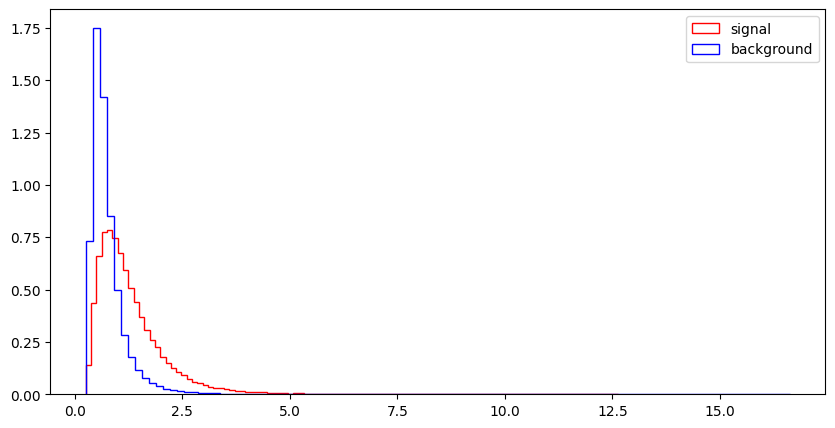

l_1_eta


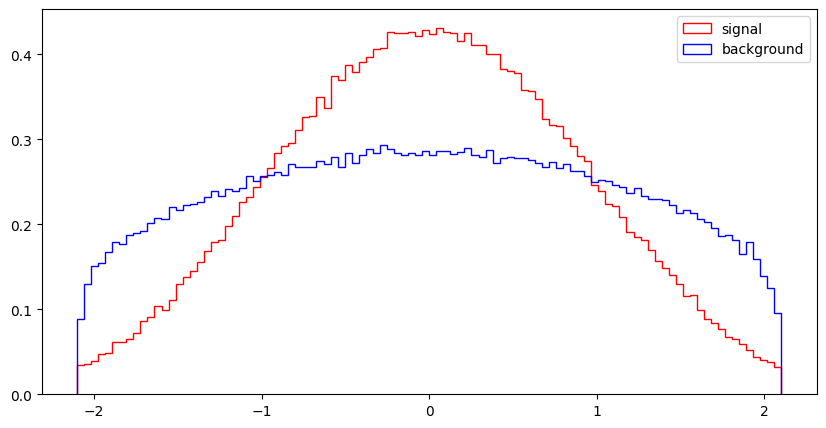

l_1_phi


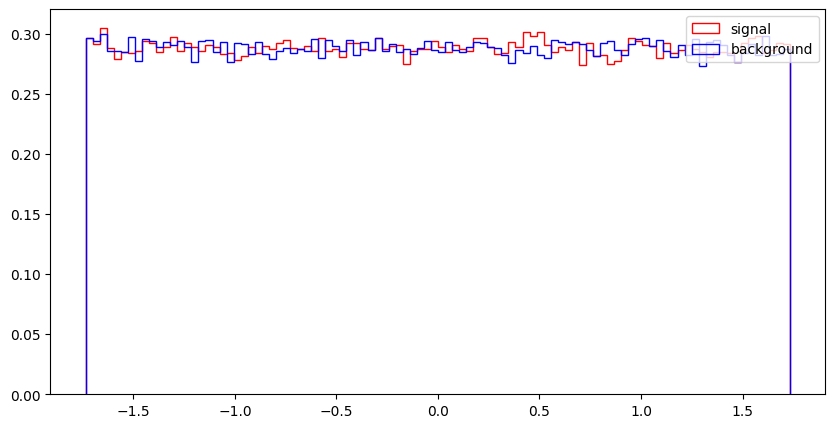

l_2_pT


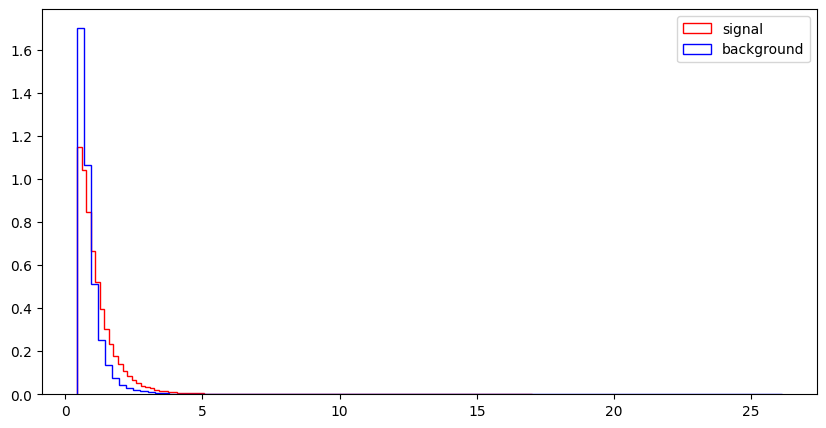

l_2_eta


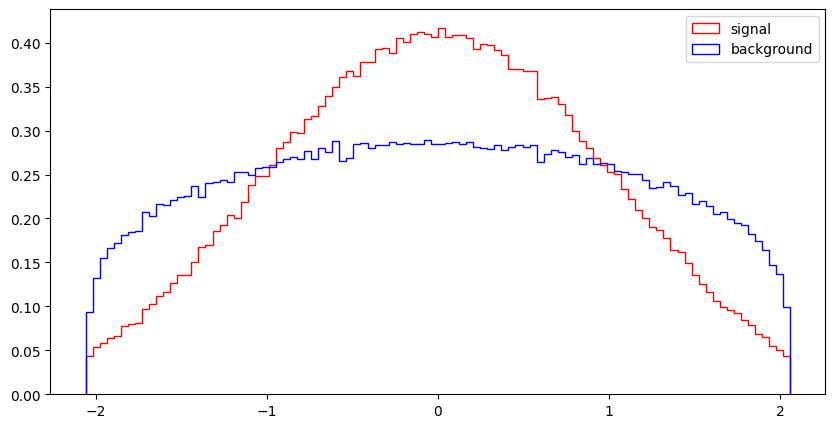

l_2_phi


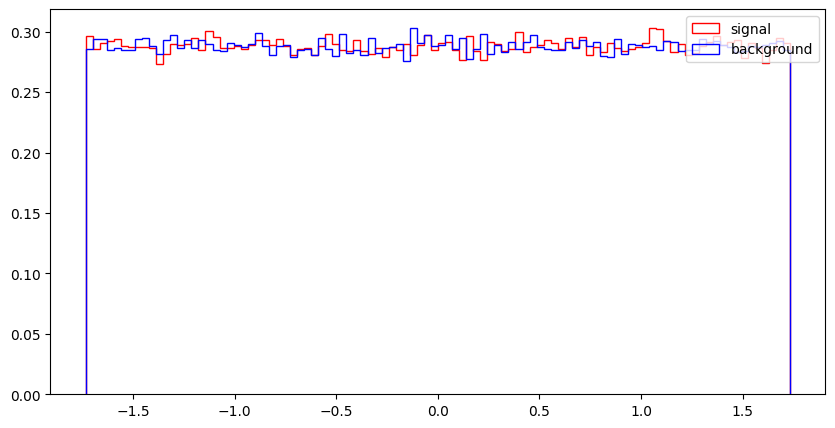

MET


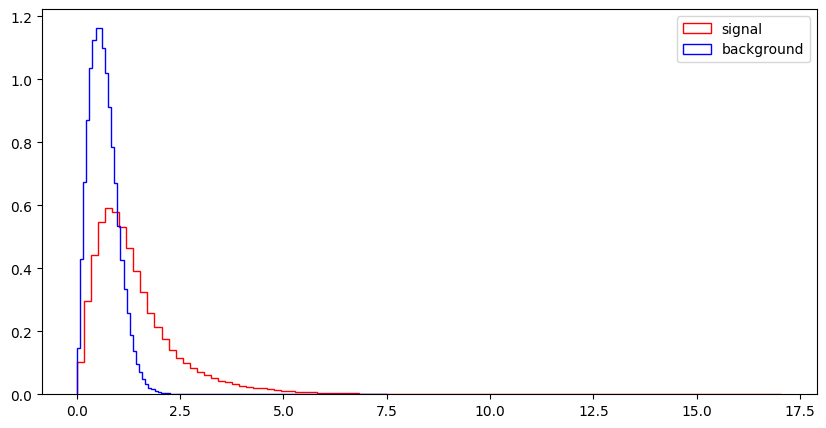

MET_phi


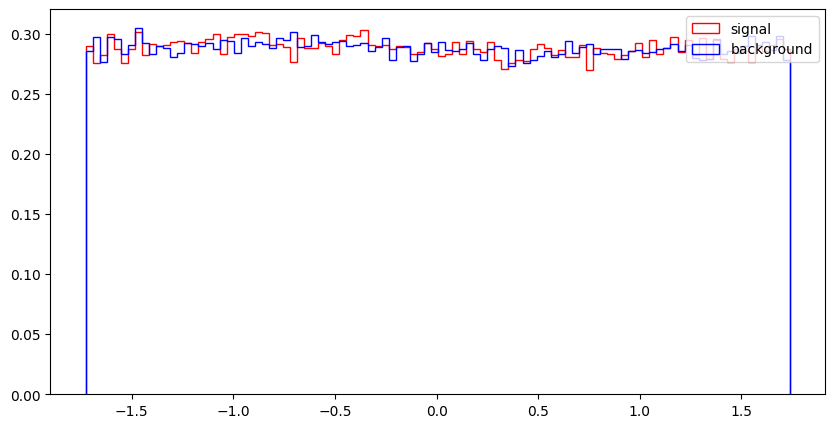

MET_rel


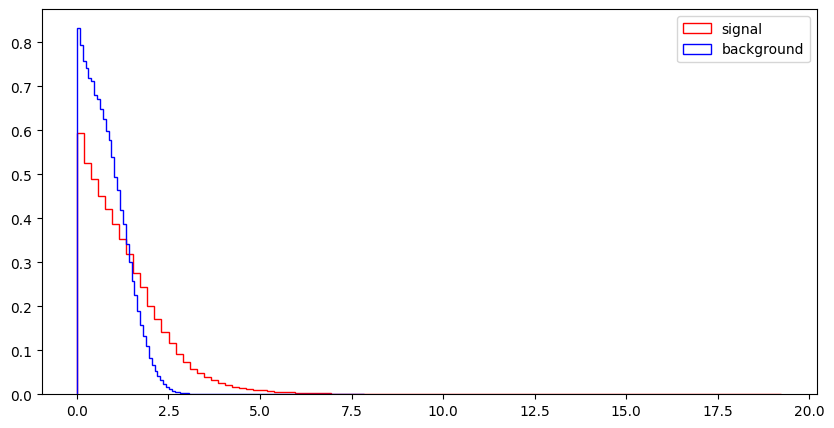

axial_MET


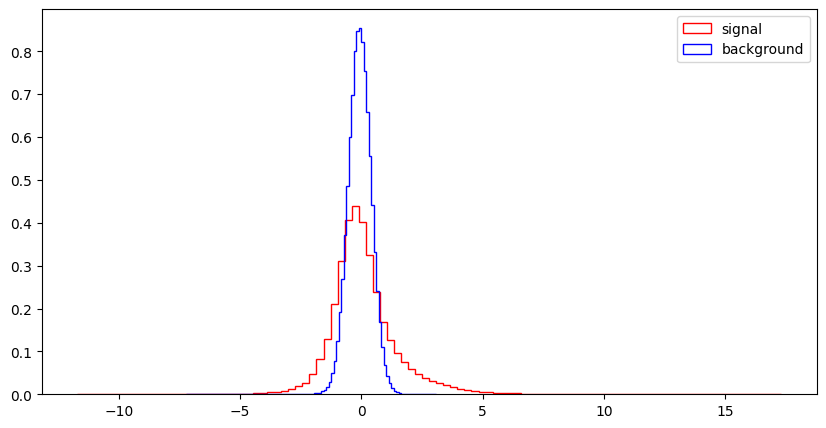

M_R


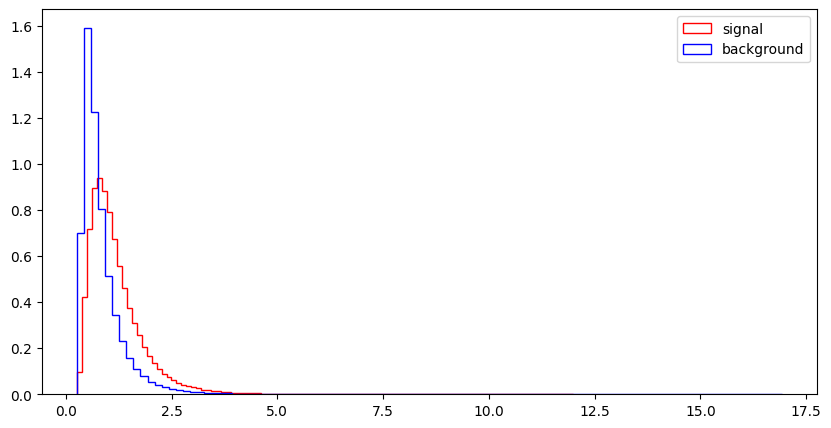

M_TR_2


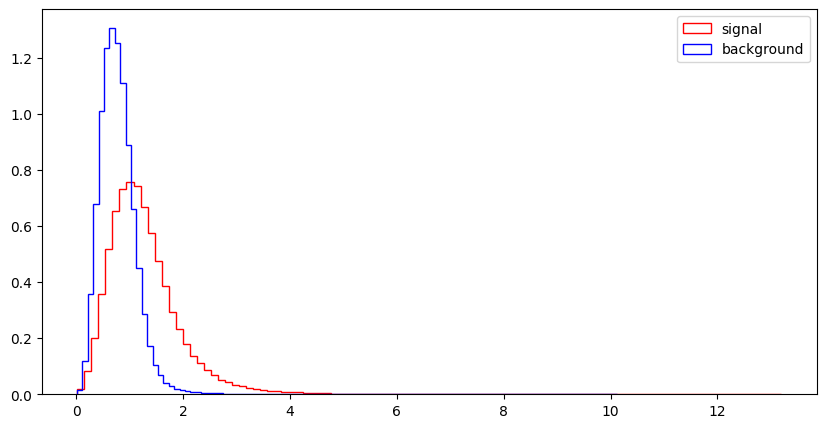

R


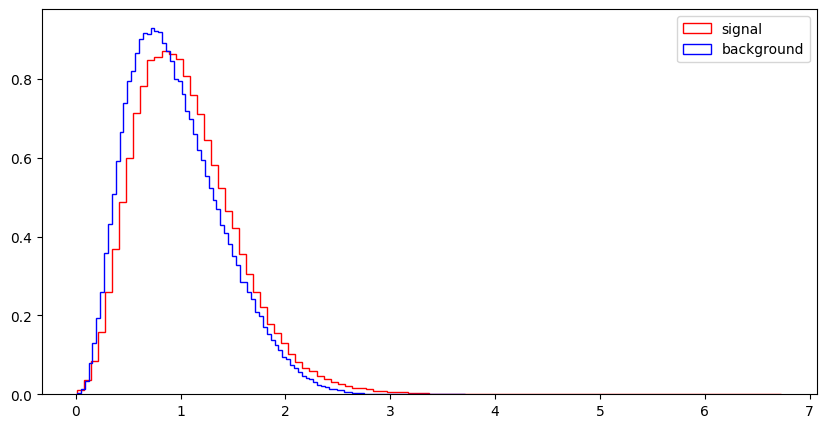

MT2


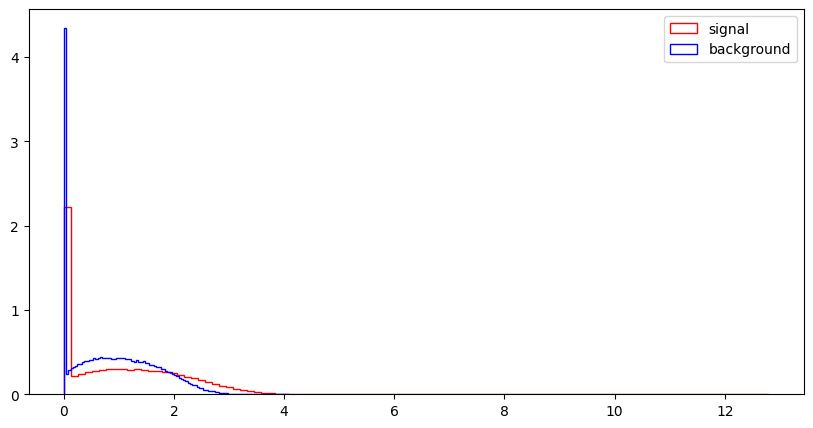

S_R


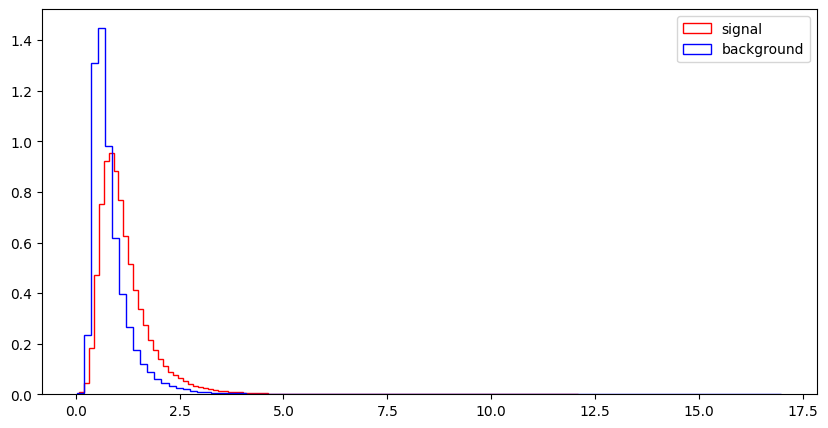

M_Delta_R


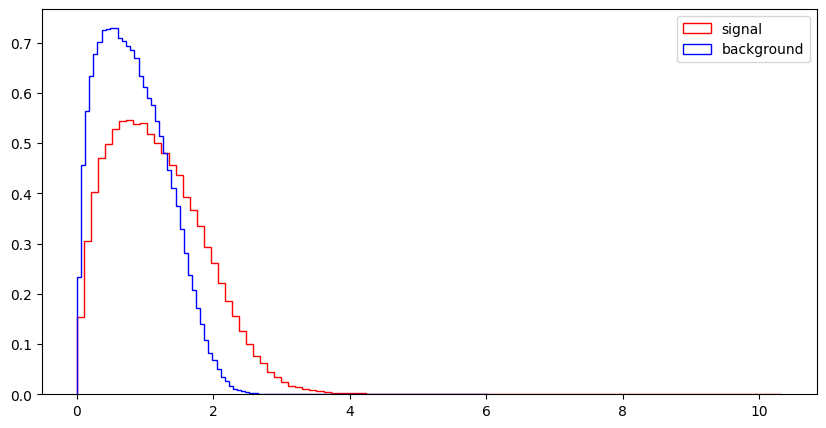

dPhi_r_b


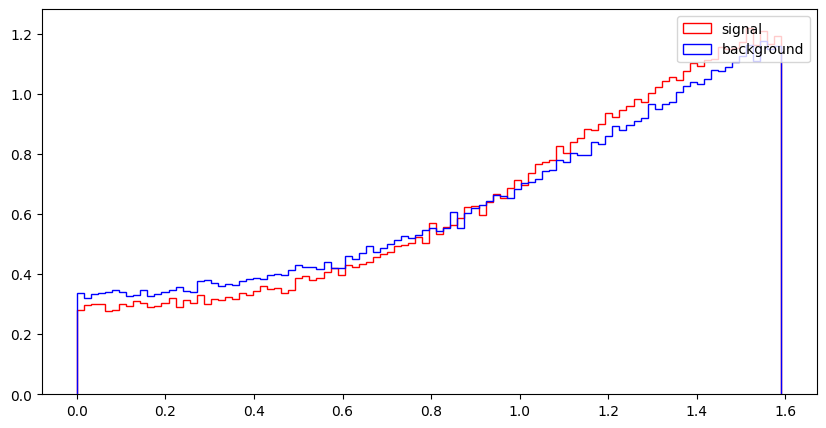

cos_theta_r1


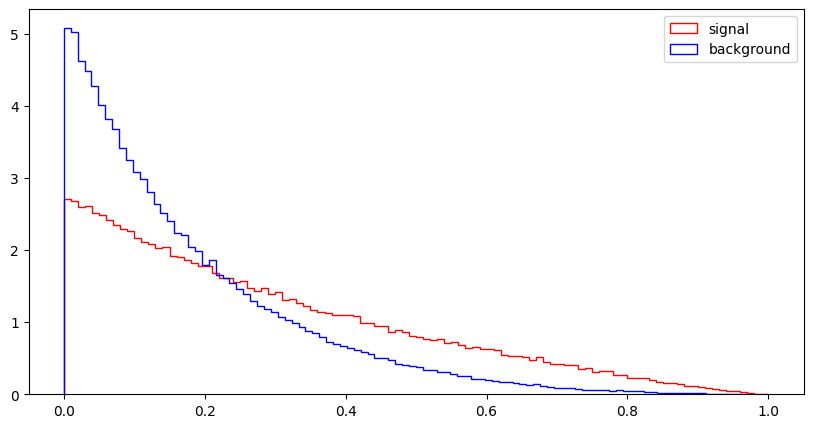

In [101]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

### Setup used by the exercises below

In [102]:
import sys, subprocess, importlib
r = subprocess.run([sys.executable, "-m", "pip", "install", "tabulate"], capture_output=True, text=True)
print("kernel python:", sys.executable)
print(r.stdout[-400:], r.stderr[-800:])
importlib.invalidate_caches()
import tabulate
print("tabulate", tabulate.__version__)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

LowNames = list(RawNames)
HighNames = [v for v in VarNames[1:] if v not in RawNames]
AllNames = LowNames + HighNames
col = {v: i for i, v in enumerate(AllNames)}
Xs = df_sig[AllNames].to_numpy()
Xb = df_bkg[AllNames].to_numpy()
Mu = {v: float(df[v].mean()) for v in AllNames}
SCENARIOS = {1: (10, 100), 2: (100, 1000), 3: (1000, 10000), 4: (10000, 100000)}
KINDS = {1: "x > xc", 2: "x < xc", 3: "|x-mu| > xc", 4: "|x-mu| < xc"}
print(len(df), "events:", len(df_sig), "signal,", len(df_bkg), "background")

kernel python: /Users/shukranmunir/Data-3402/.venv/bin/python3
You should consider upgrading via the '/Users/shukranmunir/Data-3402/.venv/bin/python3 -m pip install --upgrade pip' command.

tabulate 0.9.0
500000 events: 229245 signal, 270755 background


## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

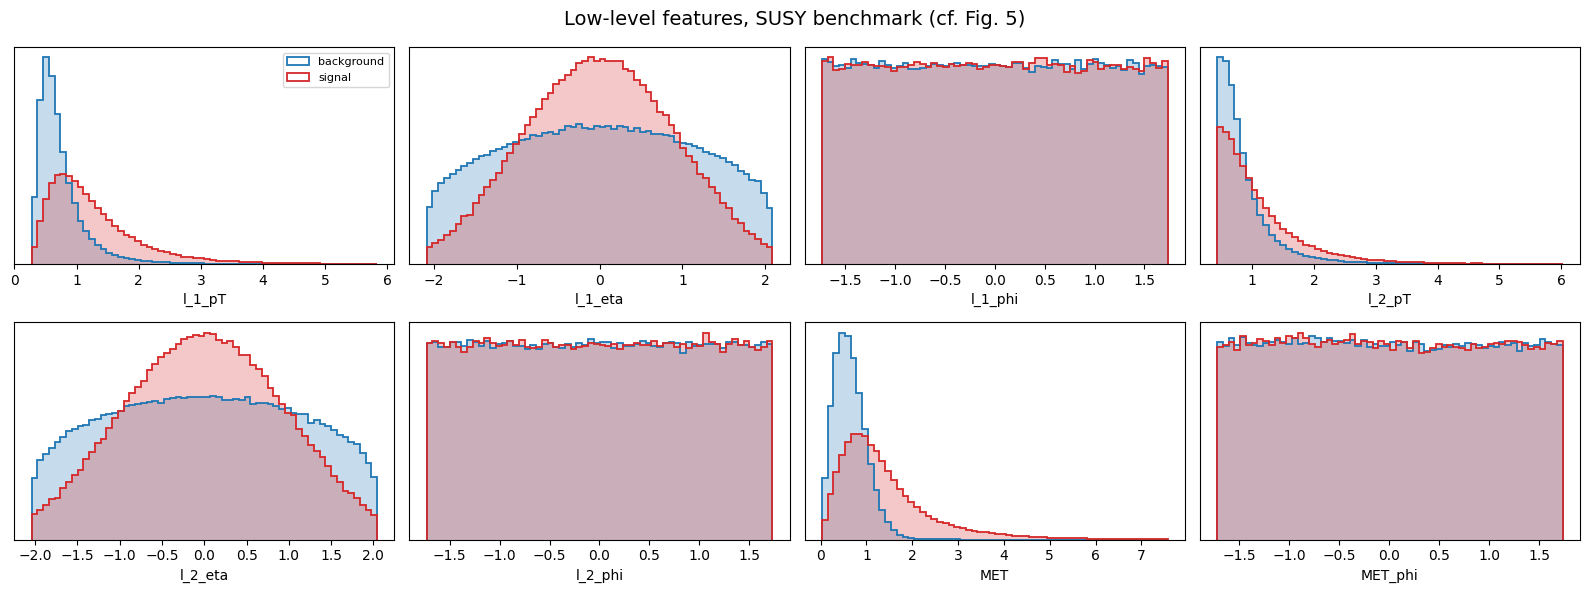

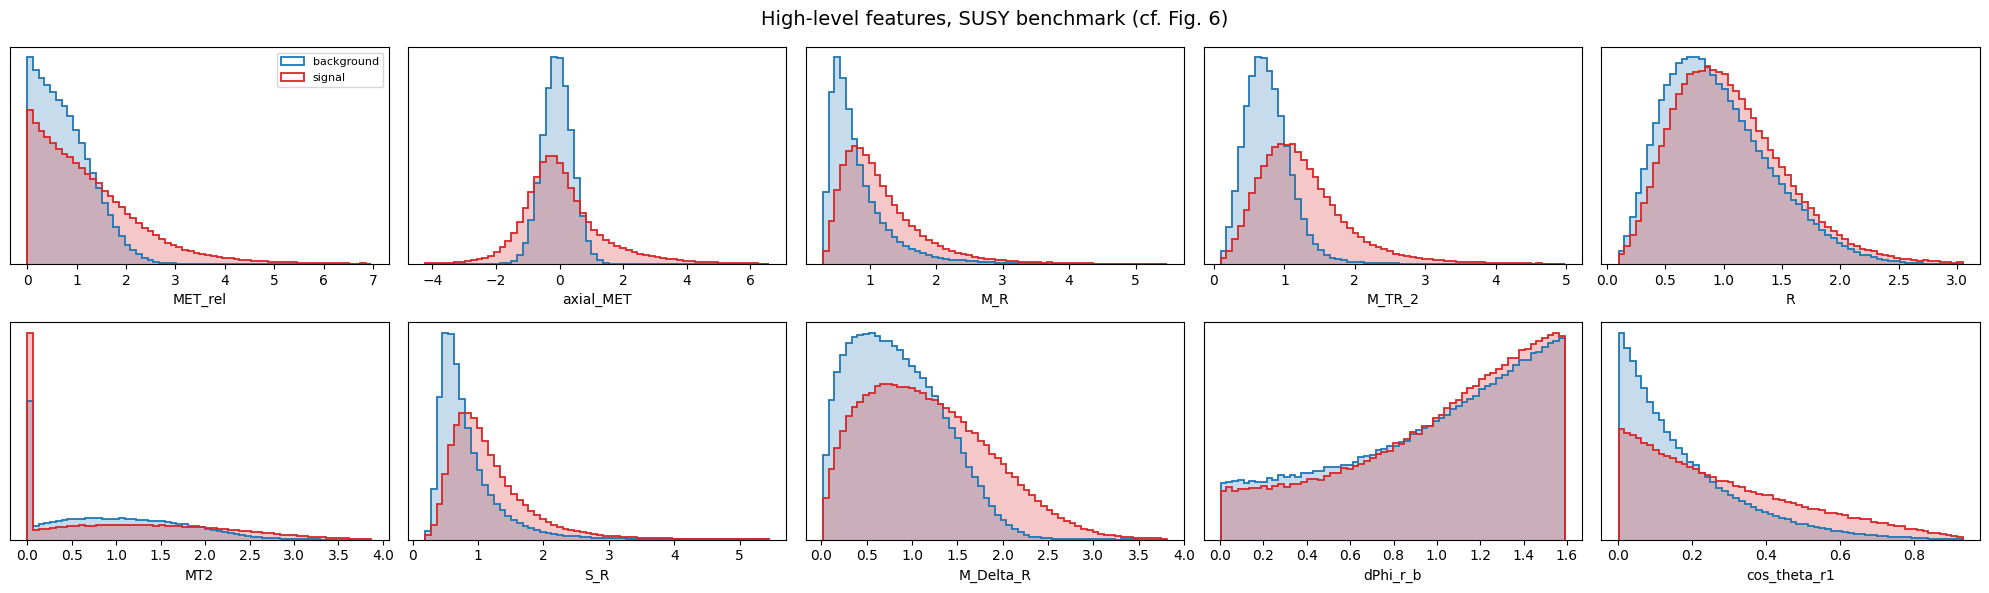

In [103]:
def hist_grid(names, shape, title, bins=60):
    fig, axes = plt.subplots(*shape, figsize=(4 * shape[1], 3 * shape[0]))
    flat = axes.ravel()
    for ax, v in zip(flat, names):
        lo, hi = np.percentile(df[v], [0.1, 99.9])
        edges = np.linspace(lo, hi, bins + 1)
        for d, color, label in ((df_bkg, "tab:blue", "background"), (df_sig, "tab:red", "signal")):
            ax.hist(d[v], bins=edges, density=True, histtype="stepfilled", color=color, alpha=0.25)
            ax.hist(d[v], bins=edges, density=True, histtype="step", color=color, label=label, linewidth=1.3)
        ax.set_xlabel(v)
        ax.set_yticks([])
    for ax in flat[len(names):]:
        ax.axis("off")
    flat[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()


hist_grid(LowNames, (2, 4), "Low-level features, SUSY benchmark (cf. Fig. 5)")
hist_grid(HighNames, (2, 5), "High-level features, SUSY benchmark (cf. Fig. 6)")

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

#### Part a

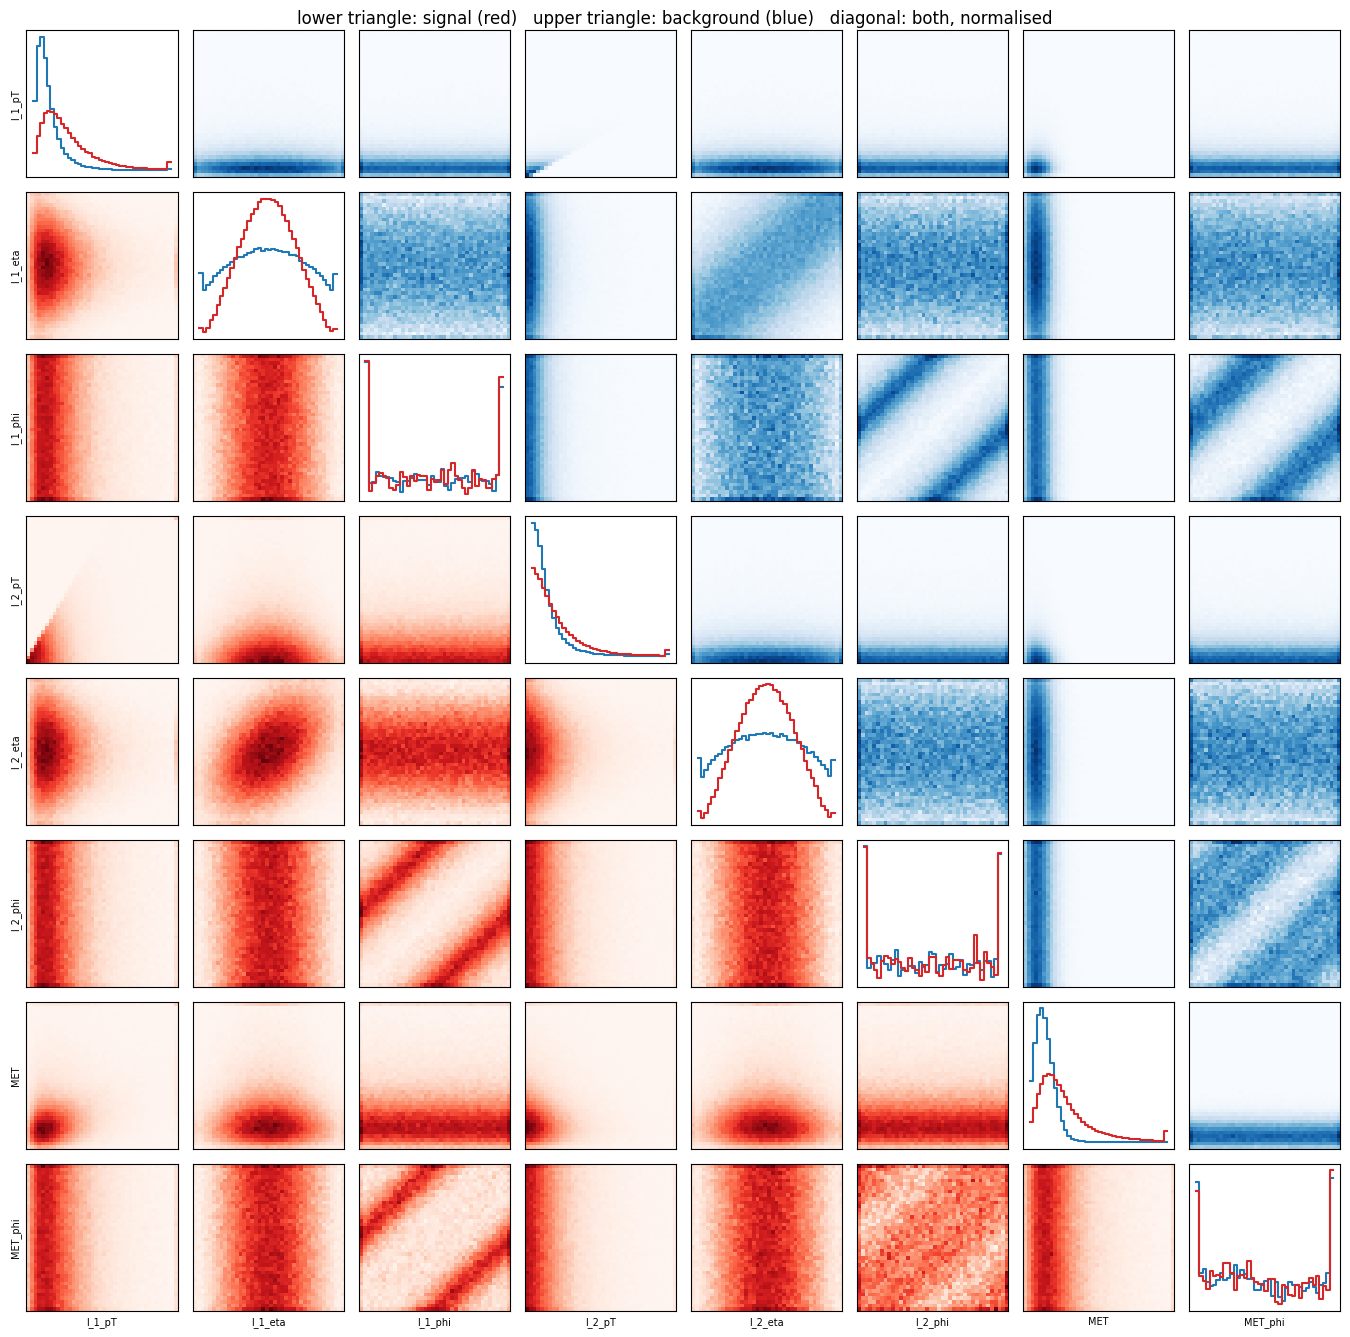

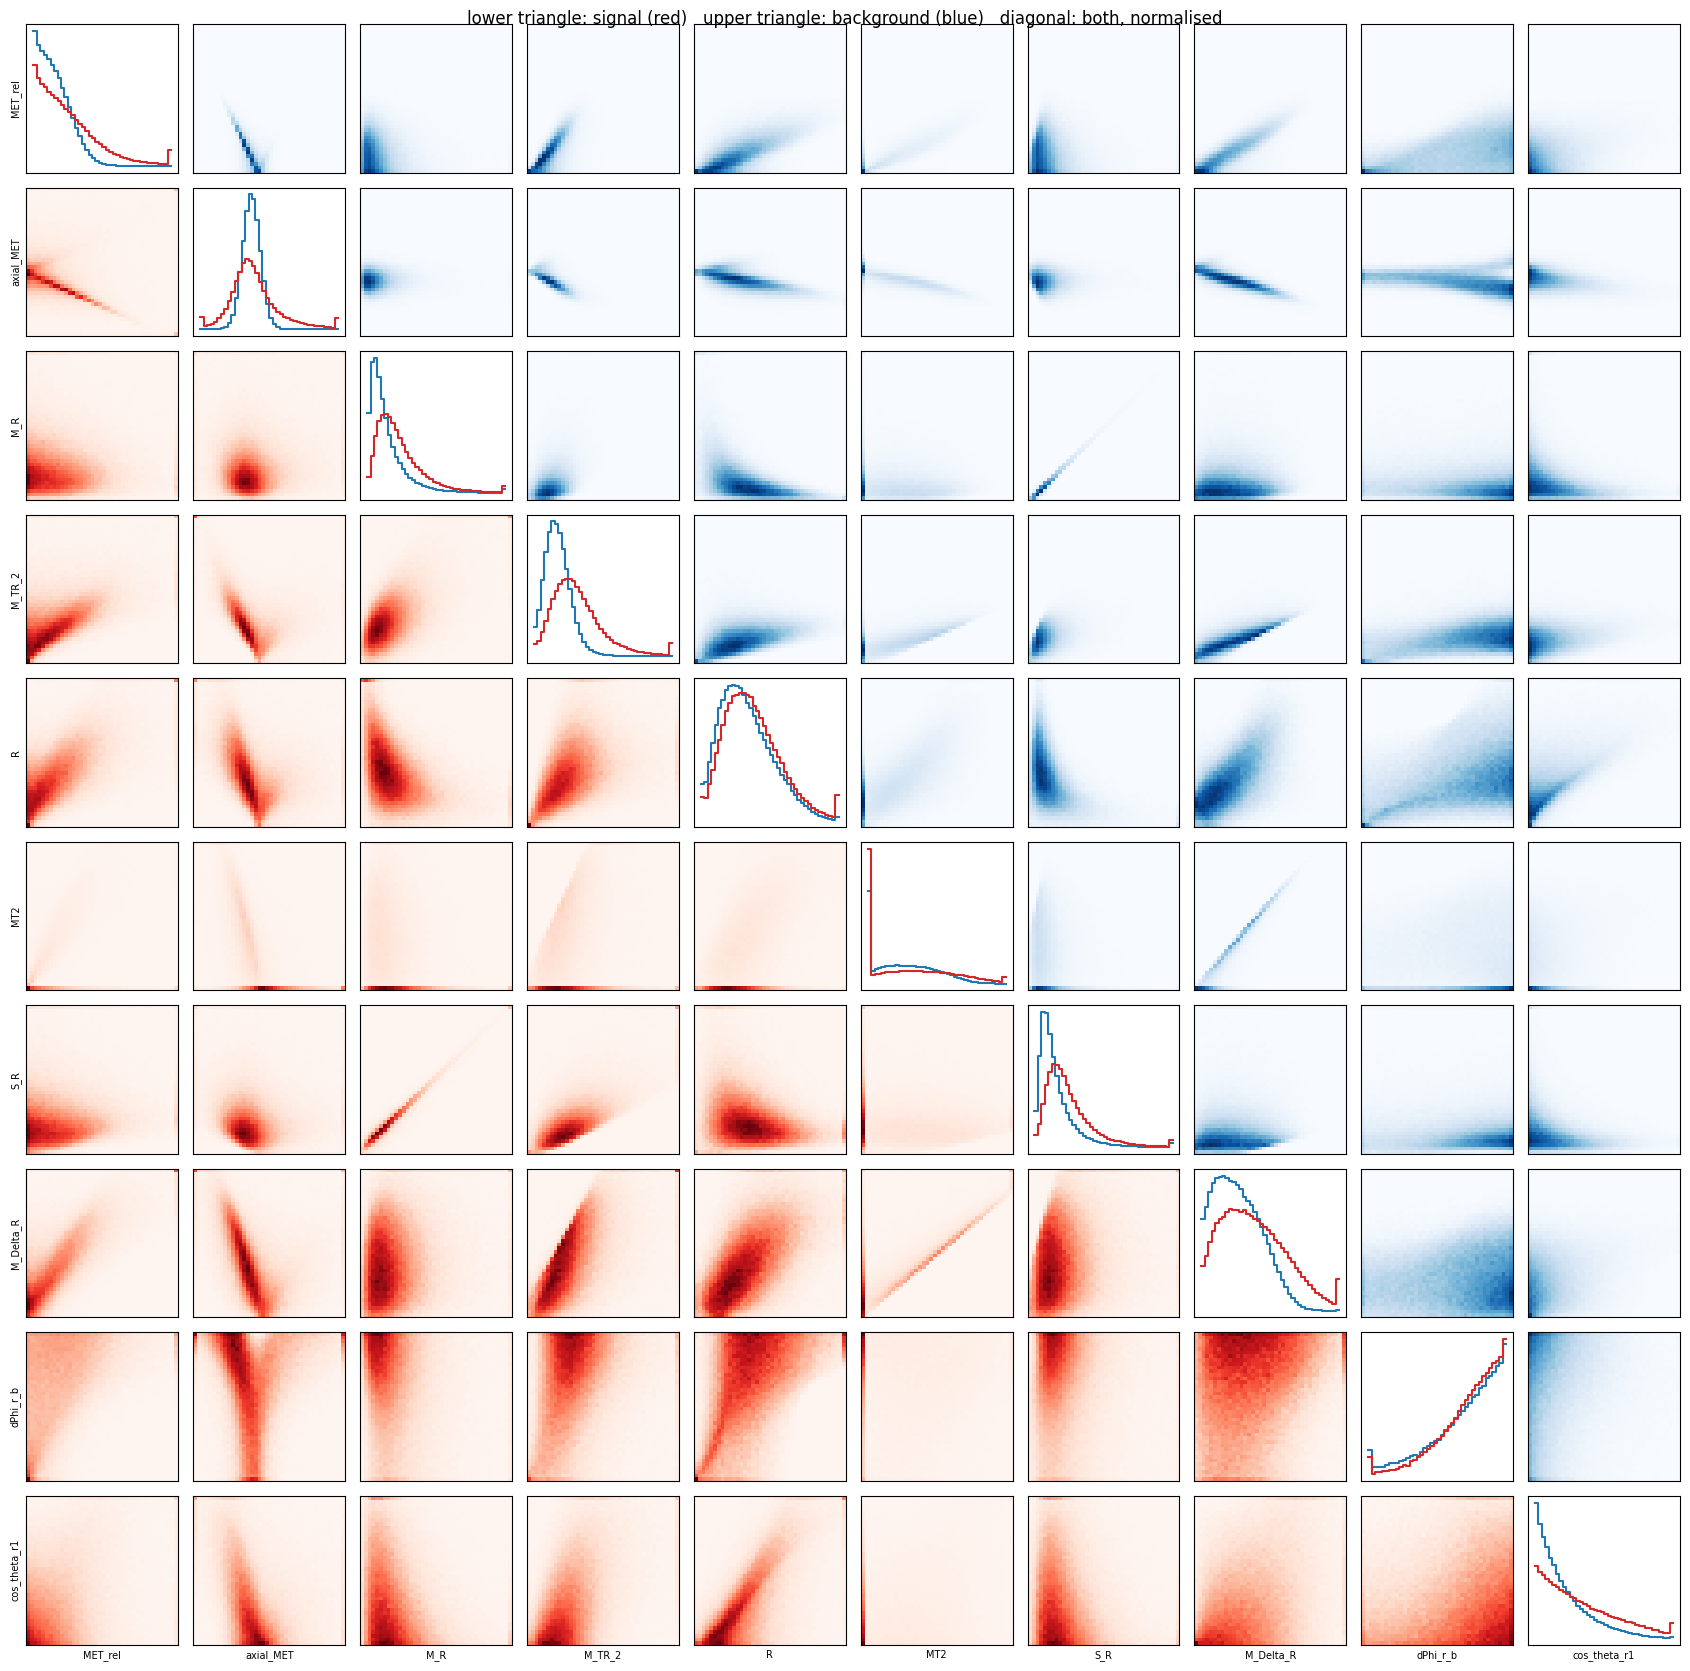

In [104]:
def bin_index(x, lo, hi, nb):
    return np.clip(((x - lo) / (hi - lo) * nb).astype(np.int64), 0, nb - 1)


def pair_plot(names, nb=40, nmax=None, seed=0, show=True):
    k = len(names)
    xs = df_sig[names].to_numpy()
    xb = df_bkg[names].to_numpy()
    if nmax is not None:
        rng = np.random.default_rng(seed)
        xs = xs[rng.choice(len(xs), min(nmax, len(xs)), replace=False)]
        xb = xb[rng.choice(len(xb), min(nmax, len(xb)), replace=False)]
    lims = [np.percentile(np.concatenate([xs[:, i], xb[:, i]]), [0.5, 99.5]) for i in range(k)]
    ix_s = np.stack([bin_index(xs[:, i], *lims[i], nb) for i in range(k)], axis=1)
    ix_b = np.stack([bin_index(xb[:, i], *lims[i], nb) for i in range(k)], axis=1)
    fig, axes = plt.subplots(k, k, figsize=(1.7 * k, 1.7 * k))
    for i in range(k):
        for j in range(k):
            ax = axes[i, j]
            if i == j:
                edges = np.linspace(*lims[i], nb + 1)
                for ix, color in ((ix_b, "tab:blue"), (ix_s, "tab:red")):
                    c = np.bincount(ix[:, i], minlength=nb) / len(ix)
                    ax.step(edges, np.append(c, c[-1]), where="post", color=color)
            else:
                ix, cmap = (ix_s, "Reds") if i > j else (ix_b, "Blues")
                counts = np.bincount(ix[:, j] * nb + ix[:, i], minlength=nb * nb).reshape(nb, nb)
                ax.imshow(counts.T, origin="lower", aspect="auto", cmap=cmap, extent=[*lims[j], *lims[i]])
            ax.set_xticks([])
            ax.set_yticks([])
            if i == k - 1:
                ax.set_xlabel(names[j], fontsize=7)
            if j == 0:
                ax.set_ylabel(names[i], fontsize=7)
    fig.suptitle("lower triangle: signal (red)   upper triangle: background (blue)   diagonal: both, normalised")
    fig.tight_layout()
    if show:
        plt.show()
        return None
    return fig


pair_plot(LowNames)
pair_plot(HighNames)

#### Part b

In [105]:
def pair_plot_slow(names, bins=40):
    k = len(names)
    fig, axes = plt.subplots(k, k, figsize=(1.7 * k, 1.7 * k))
    for i in range(k):
        for j in range(k):
            ax = axes[i, j]
            if i == j:
                ax.hist(df_bkg[names[i]], bins=bins, histtype="step", color="tab:blue", density=True)
                ax.hist(df_sig[names[i]], bins=bins, histtype="step", color="tab:red", density=True)
            elif i > j:
                ax.hist2d(df_sig[names[j]], df_sig[names[i]], bins=bins, cmap="Reds")
            else:
                ax.hist2d(df_bkg[names[j]], df_bkg[names[i]], bins=bins, cmap="Blues")
    plt.close(fig)


timings = {}
t0 = time.time()
pair_plot_slow(LowNames)
timings["plt.hist / plt.hist2d in every panel, all events"] = time.time() - t0
t0 = time.time()
plt.close(pair_plot(LowNames, show=False))
timings["digitise once + bincount, all events"] = time.time() - t0
t0 = time.time()
plt.close(pair_plot(LowNames, nmax=50000, show=False))
timings["digitise once + bincount, 50k events per class"] = time.time() - t0
for label, t in timings.items():
    print(f"{t:7.2f} s  {label}")

   0.90 s  plt.hist / plt.hist2d in every panel, all events
   0.37 s  digitise once + bincount, all events
   0.26 s  digitise once + bincount, 50k events per class


**Part b: what was changed.** The first version of a pair plot calls `plt.hist2d` for each of the k^2 panels, and every call re-reads the whole dataset and bins it with `np.histogram2d`. The fast `pair_plot` above makes three changes:

1. **Bin each variable once.** Every variable is converted to integer bin indices a single time (`bin_index`), and those indices are reused for every panel that variable appears in.
2. **Count with `np.bincount`.** A 2D histogram of two variables is then just `np.bincount(ix * nb + iy)`, a single O(N) pass with no sorting or searching, drawn with `imshow` instead of scatter points.
3. **Optional subsampling** (`nmax`): the shape of a 40x40 histogram is already clear with 50k events per class.

A different method that is faster still: because the bin edges are fixed and uniform, all pair histograms can be built from one pass over the data (for example `np.histogramdd` on small groups of variables, or a loop that only touches the bin-index matrix). The cost then scales with the number of events once, and not with the number of events times the number of panels.

**Timing (4.1b):** the plain `plt.hist2d` version took about 0.9 s, the digitise-once + `np.bincount` version about 0.37 s (roughly 2.4x faster), and with 50k events per class about 0.26-0.29 s (roughly 3x faster).

#### Part c

In [106]:
def rank_auc(a, b):
    r = pd.Series(np.concatenate([a, b])).rank().to_numpy()
    return (r[:len(a)].sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b))


rows = []
for v in AllNames:
    xs_, xb_ = df_sig[v].to_numpy(), df_bkg[v].to_numpy()
    a = rank_auc(xs_, xb_)
    d = rank_auc(np.abs(xs_ - Mu[v]), np.abs(xb_ - Mu[v]))
    rows.append((v, "low" if v in LowNames else "high", a, d, max(a, 1 - a, d, 1 - d)))
sep = pd.DataFrame(rows, columns=["variable", "level", "AUC of x", "AUC of |x-mu|", "separation"])
display(sep.sort_values("separation", ascending=False).reset_index(drop=True).round(3))

,variable,level,AUC of x,AUC of |x-mu|,separation
0,MET,low,0.771,0.572,0.771
1,l_1_pT,low,0.764,0.505,0.764
2,M_TR_2,high,0.758,0.568,0.758
3,axial_MET,high,0.498,0.716,0.716
4,M_R,high,0.705,0.457,0.705
5,S_R,high,0.699,0.457,0.699
6,cos_theta_r1,high,0.645,0.547,0.645
7,M_Delta_R,high,0.641,0.567,0.641
8,MET_rel,high,0.630,0.604,0.630
9,l_2_pT,low,0.623,0.528,0.623


**Answer (4.1c):** On their own, the best separators are the low-level `MET` (AUC 0.771) and `l_1_pT` (0.764), then the high-level `M_TR_2` (0.758). `axial_MET` (0.716), `M_R` (0.705) and `S_R` (0.699) come next; for `axial_MET` the signal differs through |x - mu| (a wider distribution), not through a shift. The three azimuthal angles (`l_1_phi`, `l_2_phi`, `MET_phi`, AUC 0.500), `dPhi_r_b` (0.517) and `R` (0.561) barely separate signal from background. So the hand-made high-level features are not uniformly better than the raw ones.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [107]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


#### Part a

In [108]:
import tabulate
print("tabulate is installed:", tabulate.__version__)

tabulate is installed: 0.9.0


#### Parts b, c, d

In [109]:
import tabulate


def show_table(rows, headers, floatfmt=".4g"):
    display(HTML(tabulate.tabulate(rows, headers=headers, tablefmt="html", floatfmt=floatfmt)))


def cov_corr_tables(data, names, label, sig_figs=3):
    x = data[names].to_numpy().T
    cov = np.cov(x)
    corr = np.corrcoef(x)
    for title, m, fmt in ((f"Covariance matrix: {label}", cov, f".{sig_figs}g"),
                          (f"Correlation matrix: {label}", corr, "+.2f")):
        display(HTML(f"<h4>{title}</h4>"))
        show_table([[n] + list(r) for n, r in zip(names, m)], [""] + names, floatfmt=fmt)
    return cov, corr


cov_all, corr_all = cov_corr_tables(df, AllNames, "all observables")
cov_low, corr_low = cov_corr_tables(df, LowNames, "low-level features")
cov_high, corr_high = cov_corr_tables(df, HighNames, "high-level features")

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,+1.00,-0.00,+0.00,+0.68,-0.00,+0.00,+0.38,-0.00,+0.16,-0.01,+0.85,+0.72,-0.19,-0.02,+0.81,+0.23,-0.16,+0.16
l_1_eta,-0.00,+1.00,-0.00,-0.00,+0.41,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,+0.00,+0.00,-0.00,-0.00,-0.00,+0.00
l_1_phi,+0.00,-0.00,+1.00,+0.00,+0.00,-0.27,+0.00,-0.18,+0.00,-0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
l_2_pT,+0.68,-0.00,+0.00,+1.00,-0.00,+0.00,+0.14,-0.00,-0.00,+0.08,+0.80,+0.43,-0.32,-0.12,+0.80,+0.01,-0.01,-0.22
l_2_eta,-0.00,+0.41,+0.00,-0.00,+1.00,+0.00,+0.00,-0.00,+0.00,-0.00,-0.00,+0.00,+0.00,+0.00,-0.00,+0.00,-0.00,+0.00
l_2_phi,+0.00,-0.00,-0.27,+0.00,+0.00,+1.00,-0.00,-0.04,+0.00,-0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,-0.00,+0.00
MET,+0.38,-0.00,+0.00,+0.14,+0.00,-0.00,+1.00,-0.00,+0.70,+0.18,+0.26,+0.72,+0.46,+0.21,+0.31,+0.58,+0.38,+0.42
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,+1.00,-0.01,-0.00,-0.00,-0.00,-0.00,+0.00,-0.00,-0.00,-0.00,+0.00
MET_rel,+0.16,-0.00,+0.00,-0.00,+0.00,+0.00,+0.70,-0.01,+1.00,-0.13,+0.08,+0.58,+0.59,+0.54,+0.15,+0.75,+0.38,+0.32
axial_MET,-0.01,-0.00,-0.00,+0.08,-0.00,-0.00,+0.18,-0.00,-0.13,+1.00,+0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,+1.00,-0.00,+0.00,+0.68,-0.00,+0.00,+0.38,-0.00
l_1_eta,-0.00,+1.00,-0.00,-0.00,+0.41,-0.00,-0.00,-0.00
l_1_phi,+0.00,-0.00,+1.00,+0.00,+0.00,-0.27,+0.00,-0.18
l_2_pT,+0.68,-0.00,+0.00,+1.00,-0.00,+0.00,+0.14,-0.00
l_2_eta,-0.00,+0.41,+0.00,-0.00,+1.00,+0.00,+0.00,-0.00
l_2_phi,+0.00,-0.00,-0.27,+0.00,+0.00,+1.00,-0.00,-0.04
MET,+0.38,-0.00,+0.00,+0.14,+0.00,-0.00,+1.00,-0.00
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,+1.00


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537
M_R,0.0437,0.0171,0.392,0.21,-0.113,-0.0365,0.38,0.0739,-0.029,-0.0143
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.0581,0.0517
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.0834,0.165,0.0871,0.0582
MT2,0.409,-0.461,-0.0365,0.189,0.232,0.738,-0.011,0.433,0.0209,0.0446
S_R,0.0823,-0.0414,0.38,0.228,-0.0834,-0.011,0.382,0.0958,-0.00346,-0.0104
M_Delta_R,0.415,-0.233,0.0739,0.242,0.165,0.433,0.0958,0.389,0.0422,0.0392
dPhi_r_b,0.146,-0.0251,-0.029,0.0581,0.0871,0.0209,-0.00346,0.0422,0.19,0.00908
cos_theta_r1,0.0553,-0.0537,-0.0143,0.0517,0.0582,0.0446,-0.0104,0.0392,0.00908,0.0388


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,+1.00,-0.13,+0.08,+0.58,+0.59,+0.54,+0.15,+0.75,+0.38,+0.32
axial_MET,-0.13,+1.00,+0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27
M_R,+0.08,+0.03,+1.00,+0.58,-0.38,-0.07,+0.98,+0.19,-0.11,-0.12
M_TR_2,+0.58,-0.32,+0.58,+1.00,+0.38,+0.38,+0.64,+0.67,+0.23,+0.45
R,+0.59,-0.38,-0.38,+0.38,+1.00,+0.57,-0.29,+0.56,+0.42,+0.63
MT2,+0.54,-0.54,-0.07,+0.38,+0.57,+1.00,-0.02,+0.81,+0.06,+0.26
S_R,+0.15,-0.07,+0.98,+0.64,-0.29,-0.02,+1.00,+0.25,-0.01,-0.09
M_Delta_R,+0.75,-0.37,+0.19,+0.67,+0.56,+0.81,+0.25,+1.00,+0.16,+0.32
dPhi_r_b,+0.38,-0.06,-0.11,+0.23,+0.42,+0.06,-0.01,+0.16,+1.00,+0.11
cos_theta_r1,+0.32,-0.27,-0.12,+0.45,+0.63,+0.26,-0.09,+0.32,+0.11,+1.00


**Answer (4.2):** The low-level features are almost independent of each other. The exceptions are the two lepton momenta (`l_1_pT`-`l_2_pT` +0.68), `MET` with `l_1_pT` (+0.38), the two lepton pseudorapidities (+0.41), and small anti-correlations between the azimuthal angles (`l_1_phi`-`l_2_phi` -0.27, `l_1_phi`-`MET_phi` -0.18), because the visible and invisible particles tend to go in opposite directions around the beam. The high-level features are computed from the low-level ones, so they are strongly correlated with them and with each other: `M_R`-`S_R` +0.98, `l_1_pT`-`M_R` +0.85, `l_1_pT`-`S_R` +0.81, `MT2`-`M_Delta_R` +0.81, `l_2_pT`-`M_R` +0.80, `MET_rel`-`M_Delta_R` +0.75, `MET`-`M_TR_2` +0.72 and `MET`-`MET_rel` +0.70.

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

#### Exercise 5.1

In [110]:
def transform(x, kind, mu):
    return np.abs(x - mu) if kind in (3, 4) else x


def passes(x, kind, xc, mu):
    t = transform(x, kind, mu)
    return t > xc if kind in (1, 3) else t < xc


def efficiency(sorted_t, xc, kind):
    n = len(sorted_t)
    if kind in (1, 3):
        return 1 - np.searchsorted(sorted_t, xc, side="right") / n
    return np.searchsorted(sorted_t, xc, side="left") / n


def auc_xy(x, y):
    o = np.argsort(x)
    x = np.concatenate([[0.0], x[o], [1.0]])
    y = np.concatenate([[0.0], y[o], [1.0]])
    return float(np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2))


def cut_curves(v, kind, n=200):
    ts = np.sort(transform(Xs[:, col[v]], kind, Mu[v]))
    tb = np.sort(transform(Xb[:, col[v]], kind, Mu[v]))
    xc = np.quantile(np.concatenate([ts, tb]), np.linspace(0.001, 0.999, n))
    return xc, efficiency(ts, xc, kind), efficiency(tb, xc, kind)


best_kind, Auc = {}, {}
for v in AllNames:
    res = {k: cut_curves(v, k) for k in KINDS}
    scores = {k: auc_xy(res[k][2], res[k][1]) for k in KINDS}
    best_kind[v] = max(scores, key=scores.get)
    Auc[v] = scores[best_kind[v]]
Ranking = sorted(AllNames, key=lambda v: -Auc[v])
show_table([[v, KINDS[best_kind[v]], Auc[v]] for v in Ranking],
           ["observable", "optimal selection", "area under (FPR, TPR) curve"], floatfmt=".3f")

observable,optimal selection,"area under (FPR, TPR) curve"
MET,x > xc,0.771
l_1_pT,x > xc,0.764
M_TR_2,x > xc,0.758
axial_MET,|x-mu| > xc,0.716
M_R,x > xc,0.705
S_R,x > xc,0.699
cos_theta_r1,x > xc,0.645
M_Delta_R,x > xc,0.641
MET_rel,x > xc,0.630
l_2_pT,x > xc,0.623


**Answer (5.1):**
- **x > xc** is best for most observables: `MET`, `l_1_pT`, `M_TR_2`, `M_R`, `S_R`, `cos_theta_r1`, `M_Delta_R`, `MET_rel`, `l_2_pT`, `R` and `dPhi_r_b`. The signal produces two heavy invisible neutralinos, so it has more missing momentum, harder leptons and larger mass scales.
- **|x - mu| > xc** is best for `axial_MET` and `MT2`, where the signal distribution is wider (longer tails on both sides) rather than shifted.
- **|x - mu| < xc** is best for `l_1_eta` and `l_2_eta`: signal leptons come from heavy particles and are more central.
- The azimuthal angles `l_1_phi`, `l_2_phi` and `MET_phi` have an area of exactly 0.500 for every choice. Their distributions are flat for both signal and background, so no selection on them helps.

#### Exercise 5.2

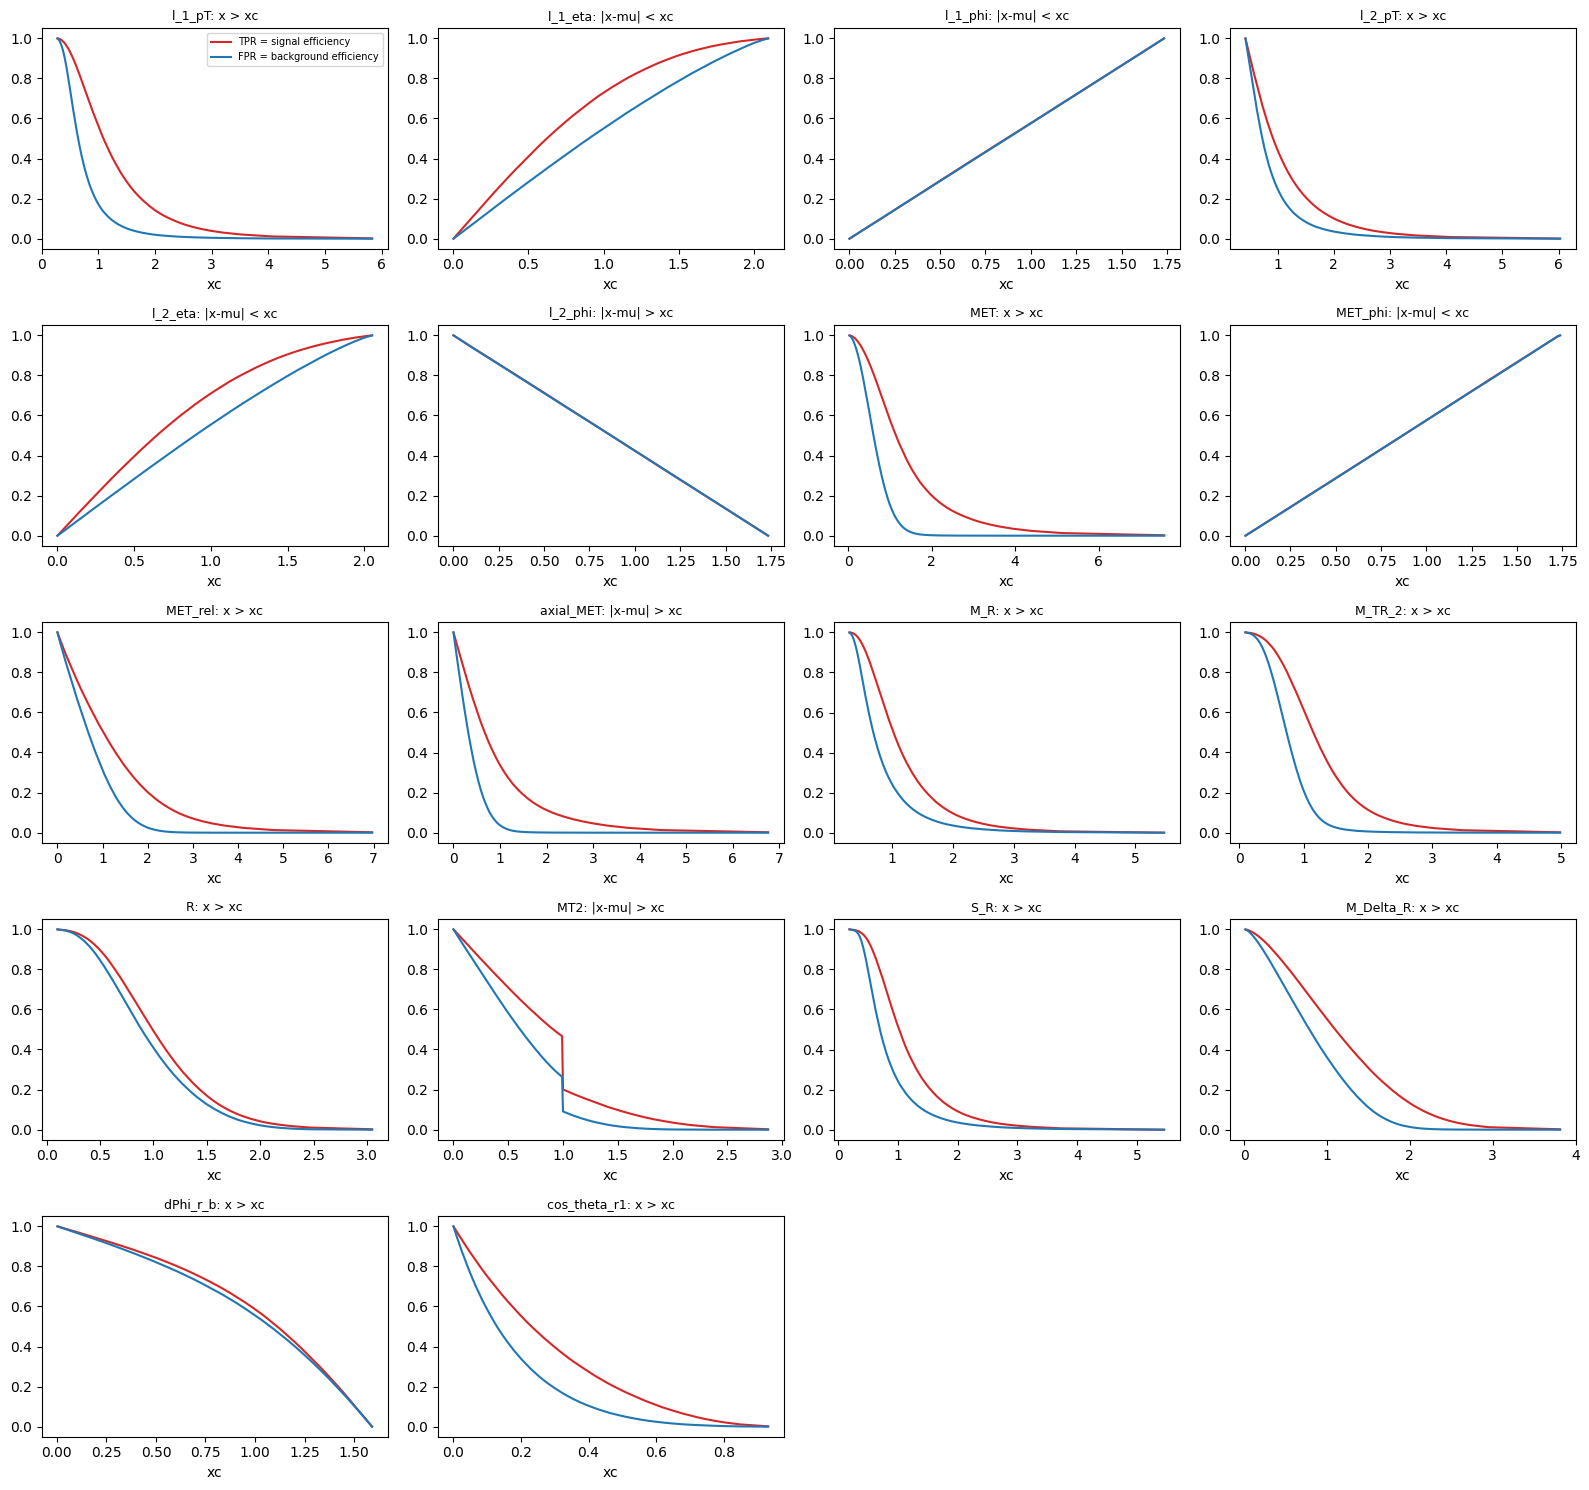

In [111]:
def grid_axes(n, ncols=4, w=4, h=3):
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows))
    flat = axes.ravel()
    for ax in flat[n:]:
        ax.axis("off")
    return fig, flat


fig, flat = grid_axes(len(AllNames))
for ax, v in zip(flat, AllNames):
    xc, es, eb = cut_curves(v, best_kind[v])
    ax.plot(xc, es, color="tab:red", label="TPR = signal efficiency")
    ax.plot(xc, eb, color="tab:blue", label="FPR = background efficiency")
    ax.set_title(f"{v}: {KINDS[best_kind[v]]}", fontsize=9)
    ax.set_xlabel("xc")
flat[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

#### Exercise 5.3

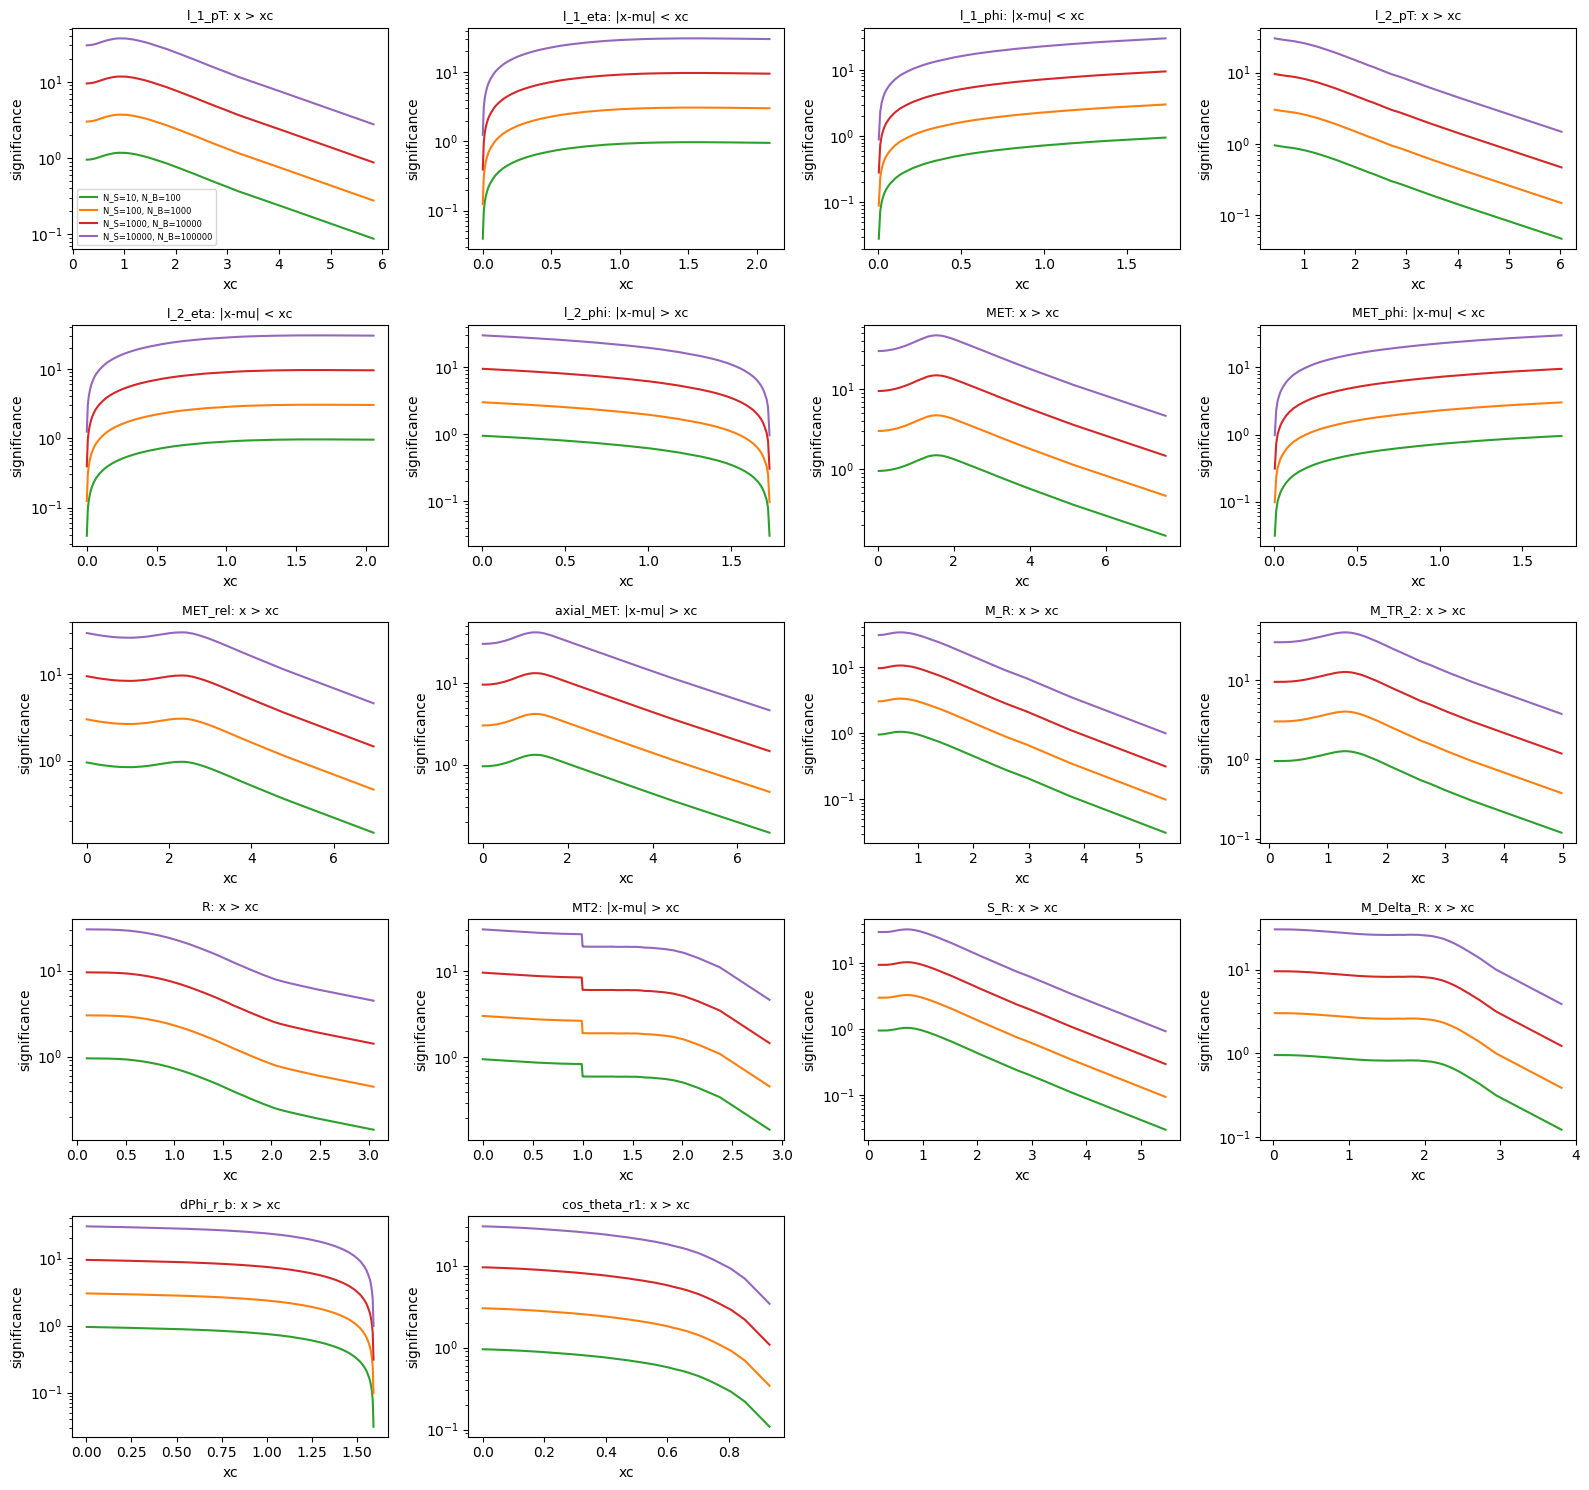

observable,selection,optimal xc,max sigma (scenario 1),max sigma (scenario 2),max sigma (scenario 3),max sigma (scenario 4)
MET,x > xc,1.543,1.499,4.74,14.99,47.4
axial_MET,|x-mu| > xc,1.218,1.318,4.168,13.18,41.68
M_TR_2,x > xc,1.302,1.271,4.02,12.71,40.2
l_1_pT,x > xc,0.9554,1.177,3.721,11.77,37.21
M_R,x > xc,0.6824,1.049,3.318,10.49,33.18
S_R,x > xc,0.7062,1.047,3.312,10.47,33.12
l_1_eta,|x-mu| < xc,1.506,0.9762,3.087,9.762,30.87
MET_rel,x > xc,2.258,0.9711,3.071,9.711,30.71
l_2_eta,|x-mu| < xc,1.637,0.9622,3.043,9.622,30.43
M_Delta_R,x > xc,0.04635,0.9536,3.015,9.536,30.15


optimal xc identical in all four scenarios: True


In [112]:
def significance(es, eb, ns, nb):
    s = es * ns
    den = np.sqrt(s + eb * nb)
    return np.divide(s, den, out=np.zeros_like(s), where=den > 0)


Best = {}
colors = ["tab:green", "tab:orange", "tab:red", "tab:purple"]
fig, flat = grid_axes(len(AllNames))
for ax, v in zip(flat, AllNames):
    xc, es, eb = cut_curves(v, best_kind[v])
    for (sc, (ns, nb)), c in zip(SCENARIOS.items(), colors):
        z = significance(es, eb, ns, nb)
        ax.plot(xc, np.where(z > 0, z, np.nan), color=c, label=f"N_S={ns}, N_B={nb}")
        i = int(np.argmax(z))
        Best[(v, sc)] = (xc[i], es[i], eb[i], z[i])
    ax.set_yscale("log")
    ax.set_title(f"{v}: {KINDS[best_kind[v]]}", fontsize=9)
    ax.set_xlabel("xc")
    ax.set_ylabel("significance")
flat[0].legend(fontsize=6)
fig.tight_layout()
plt.show()

order = sorted(AllNames, key=lambda v: -Best[(v, 3)][3])
show_table([[v, KINDS[best_kind[v]], Best[(v, 1)][0]] + [Best[(v, sc)][3] for sc in SCENARIOS] for v in order],
           ["observable", "selection", "optimal xc", "max sigma (scenario 1)", "max sigma (scenario 2)",
            "max sigma (scenario 3)", "max sigma (scenario 4)"], floatfmt=".4g")
print("optimal xc identical in all four scenarios:",
      all(np.isclose(Best[(v, 1)][0], Best[(v, sc)][0]) for v in AllNames for sc in SCENARIOS))

**Answer (5.3):** In all four scenarios N_B/N_S = 10, so sigma = sqrt(N_S) * eps_S / sqrt(eps_S + 10 eps_B). The optimal xc is therefore identical in every scenario (the notebook checks this), and each scenario's significance is sqrt(10) = 3.16 times the previous one. Without any selection sigma = 0.95, 3.02, 9.53 and 30.15. The best single cuts are:
- `MET` > 1.54: sigma = 1.50, 4.74, 14.99, 47.4
- |`axial_MET` - mu| > 1.22: 1.32, 4.17, 13.18, 41.7
- `M_TR_2` > 1.30: 1.27, 4.02, 12.71, 40.2
- `l_1_pT` > 0.955: 1.18, 3.72, 11.77, 37.2

For about half the observables (the phi angles, `R`, `dPhi_r_b`, `MT2`, `cos_theta_r1`, `M_Delta_R`, `l_2_pT`) the best "cut" keeps almost every event and the maximum sigma barely rises above the no-selection value, so on their own they are not worth cutting on.

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




#### Exercise 6.1

In [113]:
N_CUT = 4
Chosen = {}
for sc in SCENARIOS:
    names = sorted(AllNames, key=lambda v: -Best[(v, sc)][3])[:N_CUT]
    Chosen[sc] = {v: (best_kind[v], Best[(v, sc)][0]) for v in names}
for sc, d in Chosen.items():
    print(f"scenario {sc} (N_S={SCENARIOS[sc][0]}, N_B={SCENARIOS[sc][1]}):",
          [(v, KINDS[k], round(float(xc), 3)) for v, (k, xc) in d.items()])

scenario 1 (N_S=10, N_B=100): [('MET', 'x > xc', 1.543), ('axial_MET', '|x-mu| > xc', 1.218), ('M_TR_2', 'x > xc', 1.302), ('l_1_pT', 'x > xc', 0.955)]
scenario 2 (N_S=100, N_B=1000): [('MET', 'x > xc', 1.543), ('axial_MET', '|x-mu| > xc', 1.218), ('M_TR_2', 'x > xc', 1.302), ('l_1_pT', 'x > xc', 0.955)]
scenario 3 (N_S=1000, N_B=10000): [('MET', 'x > xc', 1.543), ('axial_MET', '|x-mu| > xc', 1.218), ('M_TR_2', 'x > xc', 1.302), ('l_1_pT', 'x > xc', 0.955)]
scenario 4 (N_S=10000, N_B=100000): [('MET', 'x > xc', 1.543), ('axial_MET', '|x-mu| > xc', 1.218), ('M_TR_2', 'x > xc', 1.302), ('l_1_pT', 'x > xc', 0.955)]


**Answer (6.1):** For each scenario I chose the 4 observables with the highest single-variable significance, at their optimal cuts: `MET` > 1.543, |`axial_MET` - mu| > 1.218, `M_TR_2` > 1.302 and `l_1_pT` > 0.955. The choice is the same in all four scenarios because the optimal cuts do not depend on the scenario when N_B/N_S is fixed (Exercise 5.3).

#### Exercise 6.2

In [114]:
def cut_flow(sc, cuts):
    ns, nb = SCENARIOS[sc]
    ms = np.ones(len(Xs), dtype=bool)
    mb = np.ones(len(Xb), dtype=bool)
    rows = [["no selection", 1.0, 1.0, ns, nb, ns / np.sqrt(ns + nb)]]
    for v, (kind, xc) in cuts.items():
        ms &= passes(Xs[:, col[v]], kind, xc, Mu[v])
        mb &= passes(Xb[:, col[v]], kind, xc, Mu[v])
        es, eb = ms.mean(), mb.mean()
        s, b = es * ns, eb * nb
        rows.append([f"{v} {KINDS[kind]} {xc:.3g}", es, eb, s, b, s / np.sqrt(s + b) if s + b > 0 else 0.0])
    return rows


CutFlowHeaders = ["cumulative selection", "ε_S", "ε_B", "N'_S", "N'_B", "σ_S'"]
for sc, cuts in Chosen.items():
    display(HTML(f"<h4>Scenario {sc}: N_S={SCENARIOS[sc][0]}, N_B={SCENARIOS[sc][1]}</h4>"))
    show_table(cut_flow(sc, cuts), CutFlowHeaders)

cumulative selection,ε_S,ε_B,N'_S,N'_B,σ_S'
no selection,1,1,10,100,0.9535
MET x > xc 1.54,0.3243,0.01437,3.243,1.437,1.499
axial_MET |x-mu| > xc 1.22,0.2277,0.009163,2.277,0.9163,1.274
M_TR_2 x > xc 1.3,0.1624,0.007679,1.624,0.7679,1.05
l_1_pT x > xc 0.955,0.1331,0.005278,1.331,0.5278,0.9761


cumulative selection,ε_S,ε_B,N'_S,N'_B,σ_S'
no selection,1,1,100,1000,3.015
MET x > xc 1.54,0.3243,0.01437,32.43,14.37,4.74
axial_MET |x-mu| > xc 1.22,0.2277,0.009163,22.77,9.163,4.029
M_TR_2 x > xc 1.3,0.1624,0.007679,16.24,7.679,3.32
l_1_pT x > xc 0.955,0.1331,0.005278,13.31,5.278,3.087


cumulative selection,ε_S,ε_B,N'_S,N'_B,σ_S'
no selection,1,1,1000,1e+04,9.535
MET x > xc 1.54,0.3243,0.01437,324.3,143.7,14.99
axial_MET |x-mu| > xc 1.22,0.2277,0.009163,227.7,91.63,12.74
M_TR_2 x > xc 1.3,0.1624,0.007679,162.4,76.79,10.5
l_1_pT x > xc 0.955,0.1331,0.005278,133.1,52.78,9.761


cumulative selection,ε_S,ε_B,N'_S,N'_B,σ_S'
no selection,1,1,1e+04,1e+05,30.15
MET x > xc 1.54,0.3243,0.01437,3243,1437,47.4
axial_MET |x-mu| > xc 1.22,0.2277,0.009163,2277,916.3,40.29
M_TR_2 x > xc 1.3,0.1624,0.007679,1624,767.9,33.2
l_1_pT x > xc 0.955,0.1331,0.005278,1331,527.8,30.87


**Answer (6.2):** The significance does not keep improving. In scenario 3 it goes 9.54 (no cut) -> 14.99 (after `MET`) -> 12.74 -> 10.50 -> 9.76, and the other scenarios follow the same pattern scaled by sqrt(10). After the `MET` cut, eps_S keeps falling (0.32 -> 0.13) while eps_B only falls from 0.0144 to 0.0053. Each extra cut was optimised as if it were the only cut, but the observables are correlated with `MET`, so after the first cut they mostly remove signal. This is the problem Exercise 6.3 addresses.

#### Exercise 6.3

In [115]:
SC = 3
corr_s = np.corrcoef(Xs.T)
corr_b = np.corrcoef(Xb.T)
names6 = list(Chosen[SC])
pairs = []
for a in range(len(names6)):
    for b in range(a + 1, len(names6)):
        i, j = col[names6[a]], col[names6[b]]
        pairs.append([names6[a], names6[b], corr_s[i, j], corr_b[i, j]])
pairs.sort(key=lambda p: -(abs(p[2]) + abs(p[3])))
show_table(pairs, ["observable 1", "observable 2", "correlation (signal)", "correlation (background)"], floatfmt=".3f")
A, B = pairs[0][0], pairs[0][1]
print("most correlated pair among the chosen observables:", A, B)


def apply_cuts(cuts):
    ms = np.ones(len(Xs), dtype=bool)
    mb = np.ones(len(Xb), dtype=bool)
    for v, (kind, xc) in cuts.items():
        ms &= passes(Xs[:, col[v]], kind, xc, Mu[v])
        mb &= passes(Xb[:, col[v]], kind, xc, Mu[v])
    return ms, mb


def sigma_of(ms, mb, sc=SC):
    ns, nb = SCENARIOS[sc]
    s, b = ms.mean() * ns, mb.mean() * nb
    return s / np.sqrt(s + b) if s + b > 0 else 0.0


def optimize_after(prev_s, prev_b, v, sc=SC):
    ns, nb = SCENARIOS[sc]
    kind = best_kind[v]
    ts = np.sort(transform(Xs[prev_s, col[v]], kind, Mu[v]))
    tb = np.sort(transform(Xb[prev_b, col[v]], kind, Mu[v]))
    xc = np.quantile(np.concatenate([ts, tb]), np.linspace(0.001, 0.999, 300))
    es = efficiency(ts, xc, kind) * prev_s.mean()
    eb = efficiency(tb, xc, kind) * prev_b.mean()
    z = significance(es, eb, ns, nb)
    i = int(np.argmax(z))
    return float(xc[i]), float(z[i])


cutA = (best_kind[A], Best[(A, SC)][0])
cutB = (best_kind[B], Best[(B, SC)][0])
xcB_after_A, _ = optimize_after(*apply_cuts({A: cutA}), B)
xcA_after_B, _ = optimize_after(*apply_cuts({B: cutB}), A)
cuts_ab = {A: cutA, B: (best_kind[B], xcB_after_A)}
cuts_ba = {B: cutB, A: (best_kind[A], xcA_after_B)}
rows = [
    [f"{A} alone, own optimum", cutA[1], "", sigma_of(*apply_cuts({A: cutA}))],
    [f"{B} alone, own optimum", cutB[1], "", sigma_of(*apply_cuts({B: cutB}))],
    ["both at their single-variable optimum", f"{A}: {cutA[1]:.3g}", f"{B}: {cutB[1]:.3g}", sigma_of(*apply_cuts({A: cutA, B: cutB}))],
    [f"cut {A}, then re-optimise {B}", f"{A}: {cutA[1]:.3g}", f"{B}: {xcB_after_A:.3g}", sigma_of(*apply_cuts(cuts_ab))],
    [f"cut {B}, then re-optimise {A}", f"{B}: {cutB[1]:.3g}", f"{A}: {xcA_after_B:.3g}", sigma_of(*apply_cuts(cuts_ba))],
]
show_table(rows, ["strategy", "first cut", "second cut", "σ_S' (scenario 3)"], floatfmt=".4g")

cuts = {A: cutA, B: cutB}
history = [sigma_of(*apply_cuts(cuts))]
for _ in range(4):
    for v, other in ((B, A), (A, B)):
        xc, _ = optimize_after(*apply_cuts({other: cuts[other]}), v)
        cuts[v] = (best_kind[v], xc)
    history.append(sigma_of(*apply_cuts(cuts)))
print("alternating re-optimisation, sigma after each round:", [round(float(h), 3) for h in history])

observable 1,observable 2,correlation (signal),correlation (background)
MET,M_TR_2,0.633,0.826
M_TR_2,l_1_pT,0.691,0.597
axial_MET,M_TR_2,-0.332,-0.693
MET,axial_MET,0.264,-0.654
MET,l_1_pT,0.280,0.163
axial_MET,l_1_pT,-0.039,-0.099


most correlated pair among the chosen observables: MET M_TR_2


strategy,first cut,second cut,σ_S' (scenario 3)
"MET alone, own optimum",1.5430381298065183,,14.99
"M_TR_2 alone, own optimum",1.3016711479605143,,12.71
both at their single-variable optimum,MET: 1.54,M_TR_2: 1.3,12.76
"cut MET, then re-optimise M_TR_2",MET: 1.54,M_TR_2: 0.13,14.98
"cut M_TR_2, then re-optimise MET",M_TR_2: 1.3,MET: 1.44,12.81


alternating re-optimisation, sigma after each round: [12.758, 14.984, 14.985, 14.985, 14.985]


**Answer (6.3):** Among the chosen observables, the pair where correlation does the most damage is `MET` and `M_TR_2`: correlation 0.63 in signal and 0.83 in background. (`axial_MET`-`M_TR_2` at -0.69 and `MET`-`axial_MET` at -0.65 in background are next.) In scenario 3:
- Both cuts at their single-variable optima give sigma = 12.76, *worse* than `MET` alone (14.99).
- Cutting on `MET` first and then re-optimising `M_TR_2` moves the `M_TR_2` cut down to 0.13, which keeps almost every event, and gives sigma = 14.98. Once `MET` is cut, `M_TR_2` adds no information.
- Reversing the order (`M_TR_2` > 1.30 first, then re-optimising `MET`, whose cut moves to 1.44) gives only sigma = 12.81, because the first cut stays fixed at a value that is not optimal for the combination.

So the order matters. Re-optimising each cut in turn, given the other, converges in one round to sigma = 14.985 whichever order you start in. Correlated cuts have to be optimised together, not one at a time.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



#### Exercise 7.1

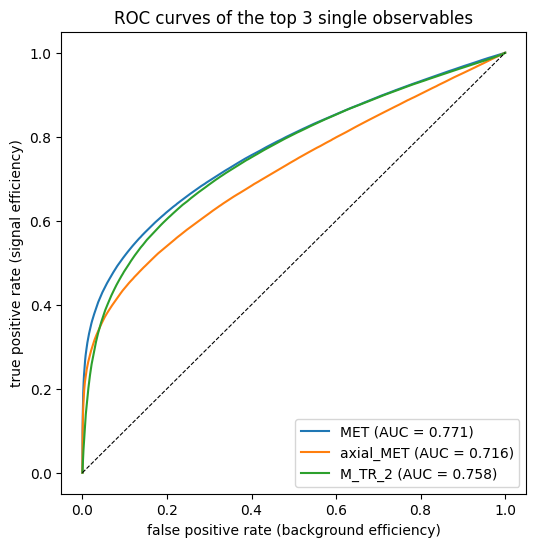

In [116]:
def score_arrays(v, ms=None, mb=None):
    kind = best_kind[v]
    sgn = 1.0 if kind in (1, 3) else -1.0
    xs = Xs[:, col[v]] if ms is None else Xs[ms, col[v]]
    xb = Xb[:, col[v]] if mb is None else Xb[mb, col[v]]
    return sgn * transform(xs, kind, Mu[v]), sgn * transform(xb, kind, Mu[v])


def roc_curve(ss, sb, n=500):
    ss, sb = np.sort(ss), np.sort(sb)
    thr = np.concatenate([[-np.inf], np.quantile(np.concatenate([ss, sb]), np.linspace(0, 1, n)), [np.inf]])
    tpr = 1 - np.searchsorted(ss, thr, side="right") / len(ss)
    fpr = 1 - np.searchsorted(sb, thr, side="right") / len(sb)
    return fpr, tpr, auc_xy(fpr, tpr)


Top3 = list(Chosen[3])[:3]
fig, ax = plt.subplots(figsize=(6, 6))
for v in Top3:
    fpr, tpr, a = roc_curve(*score_arrays(v))
    ax.plot(fpr, tpr, label=f"{v} (AUC = {a:.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("false positive rate (background efficiency)")
ax.set_ylabel("true positive rate (signal efficiency)")
ax.set_title("ROC curves of the top 3 single observables")
ax.legend(loc="lower right")
plt.show()

**Answer (7.1):** AUC: `MET` 0.771, `M_TR_2` 0.758, `axial_MET` 0.716.

#### Exercise 7.2

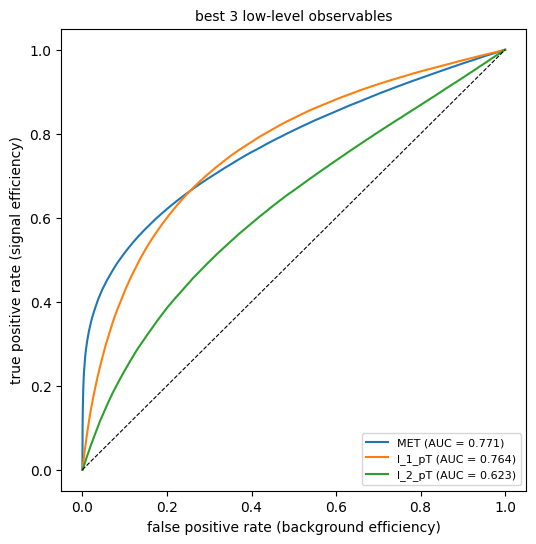

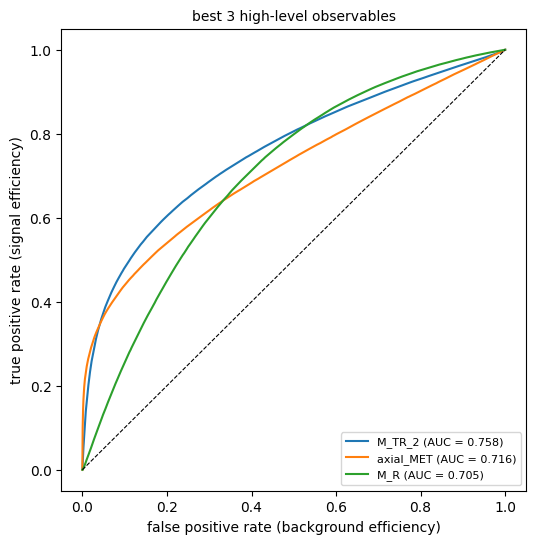

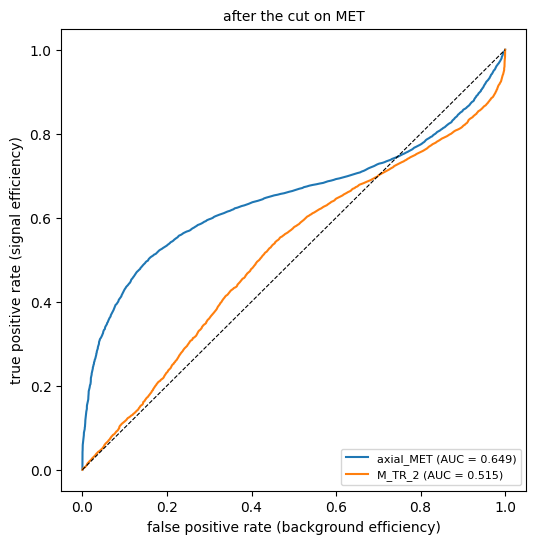

In [117]:
def roc_figure(curves, title="", ax=None):
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(6, 6))
    aucs = {}
    for label, (ss, sb) in curves.items():
        fpr, tpr, a = roc_curve(ss, sb)
        aucs[label] = a
        ax.plot(fpr, tpr, label=f"{label} (AUC = {a:.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_xlabel("false positive rate (background efficiency)")
    ax.set_ylabel("true positive rate (signal efficiency)")
    ax.set_title(title, fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
    if own:
        plt.show()
    return aucs


top_low = sorted(LowNames, key=lambda v: -Auc[v])[:3]
top_high = sorted(HighNames, key=lambda v: -Auc[v])[:3]
a_low = roc_figure({v: score_arrays(v) for v in top_low}, "best 3 low-level observables")
a_high = roc_figure({v: score_arrays(v) for v in top_high}, "best 3 high-level observables")
ms_c, mb_c = apply_cuts({Top3[0]: Chosen[3][Top3[0]]})
a_cond = roc_figure({v: score_arrays(v, ms_c, mb_c) for v in Top3[1:]}, f"after the cut on {Top3[0]}")

#### Exercise 7.3

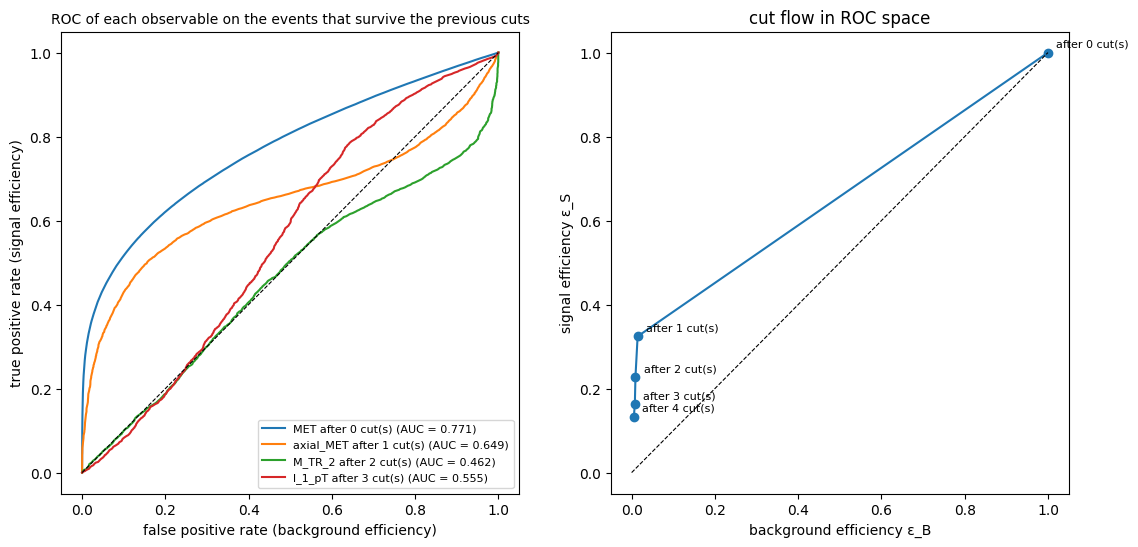

In [118]:
chain = list(Chosen[SC])
ms = np.ones(len(Xs), dtype=bool)
mb = np.ones(len(Xb), dtype=bool)
curves = {}
path = [(1.0, 1.0)]
for k, v in enumerate(chain):
    curves[f"{v} after {k} cut(s)"] = score_arrays(v, ms, mb)
    kind, xc = Chosen[SC][v]
    ms &= passes(Xs[:, col[v]], kind, xc, Mu[v])
    mb &= passes(Xb[:, col[v]], kind, xc, Mu[v])
    path.append((mb.mean(), ms.mean()))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
aucs = roc_figure(curves, "ROC of each observable on the events that survive the previous cuts", ax=ax1)
ax2.plot(*zip(*path), "o-")
for k, (x, y) in enumerate(path):
    ax2.annotate(f"after {k} cut(s)", (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax2.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax2.set_xlabel("background efficiency ε_B")
ax2.set_ylabel("signal efficiency ε_S")
ax2.set_title("cut flow in ROC space")
plt.show()

**Answer (7.3):** After each selection, the next observable has less discriminating power on the events that survive. `axial_MET` drops from AUC 0.716 to 0.649 after the `MET` cut. `M_TR_2` after two cuts has AUC 0.462, below 0.5, so on the surviving events a high `M_TR_2` is now slightly *background*-like and the cut points the wrong way. `l_1_pT` after three cuts has AUC 0.555. In the right-hand panel, every cut after the first moves the point mostly straight down (signal lost) with very little gain in background rejection, which is why the significance falls in the cut flow.

#### Exercise 7.4

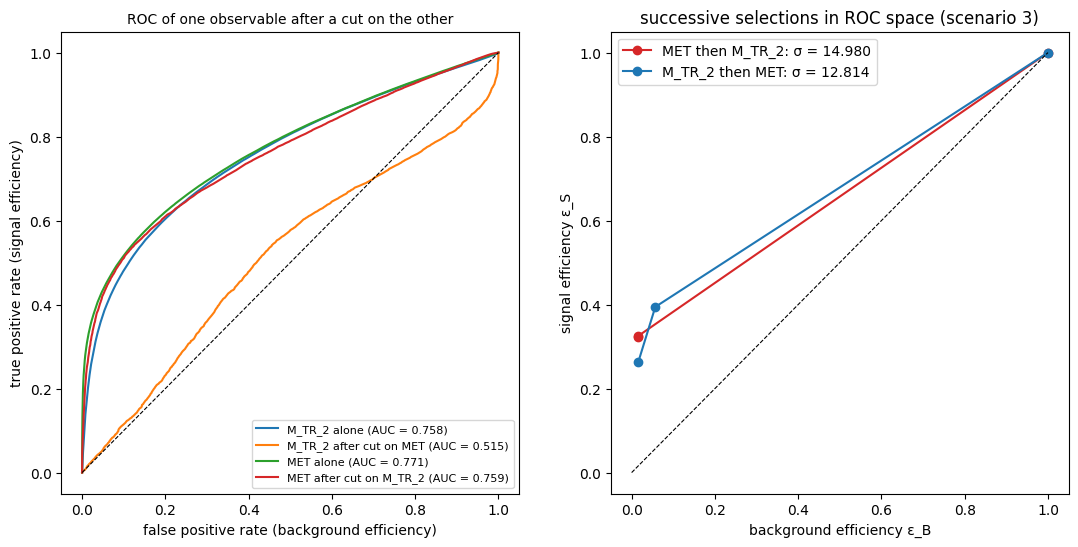

In [119]:
ms_a, mb_a = apply_cuts({A: cutA})
ms_b, mb_b = apply_cuts({B: cutB})
curves = {
    f"{B} alone": score_arrays(B),
    f"{B} after cut on {A}": score_arrays(B, ms_a, mb_a),
    f"{A} alone": score_arrays(A),
    f"{A} after cut on {B}": score_arrays(A, ms_b, mb_b),
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
aucs = roc_figure(curves, "ROC of one observable after a cut on the other", ax=ax1)
for cuts_x, first, label, color in ((cuts_ab, A, f"{A} then {B}", "tab:red"), (cuts_ba, B, f"{B} then {A}", "tab:blue")):
    first_s, first_b = apply_cuts({first: cuts_x[first]})
    end_s, end_b = apply_cuts(cuts_x)
    pts = [(1.0, 1.0), (first_b.mean(), first_s.mean()), (end_b.mean(), end_s.mean())]
    ax2.plot(*zip(*pts), "o-", color=color, label=f"{label}: σ = {sigma_of(end_s, end_b):.3f}")
ax2.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax2.set_xlabel("background efficiency ε_B")
ax2.set_ylabel("signal efficiency ε_S")
ax2.set_title("successive selections in ROC space (scenario 3)")
ax2.legend()
plt.show()

**Answer (7.4):** Order matters because the two observables are correlated but not equally informative. After the `MET` cut, `M_TR_2` has AUC 0.515 (0.758 on its own): almost nothing is left to separate. After the `M_TR_2` cut, `MET` still has AUC 0.759 (0.771 on its own). `MET` therefore carries the information in `M_TR_2`, but not the other way round. Cutting on `MET` first ends at sigma = 14.98; cutting on `M_TR_2` first ends at sigma = 12.81.

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

#### Exercise 8.1

In [ ]:
def fisher_matrices(names):
    xs = df_sig[names].to_numpy()
    xb = df_bkg[names].to_numpy()
    m1, m2 = xs.mean(axis=0), xb.mean(axis=0)
    d = (m2 - m1).reshape(-1, 1)
    SB = d @ d.T
    cs, cb = xs - m1, xb - m2
    SW = cs.T @ cs + cb.T @ cb
    return m1, m2, SB, SW


m1, m2, SB, SW = fisher_matrices(AllNames)
print("S_B and S_W are", SB.shape, "and", SW.shape)
display(pd.DataFrame(SB, index=AllNames, columns=AllNames).round(3))
display(pd.DataFrame(SW, index=AllNames, columns=AllNames).round(1))

S_B and S_W are (18, 18) and (18, 18)


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.288,0.000,0.000,0.138,0.002,0.000,0.413,-0.001,0.271,0.085,0.182,0.267,0.055,0.074,0.174,0.184,0.015,0.057
l_1_eta,0.000,0.000,0.000,0.000,0.000,0.000,0.001,-0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
l_1_phi,0.000,0.000,0.000,0.000,0.000,0.000,0.001,-0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
l_2_pT,0.138,0.000,0.000,0.066,0.001,0.000,0.198,-0.000,0.130,0.041,0.087,0.128,0.027,0.035,0.084,0.088,0.007,0.027
l_2_eta,0.002,0.000,0.000,0.001,0.000,0.000,0.002,-0.000,0.001,0.000,0.001,0.001,0.000,0.000,0.001,0.001,0.000,0.000
l_2_phi,0.000,0.000,0.000,0.000,0.000,0.000,0.001,-0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
MET,0.413,0.001,0.001,0.198,0.002,0.001,0.594,-0.001,0.389,0.123,0.262,0.383,0.079,0.106,0.250,0.264,0.022,0.081
MET_phi,-0.001,-0.000,-0.000,-0.000,-0.000,-0.000,-0.001,0.000,-0.001,-0.000,-0.000,-0.001,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
MET_rel,0.271,0.000,0.000,0.130,0.001,0.000,0.389,-0.001,0.255,0.080,0.172,0.251,0.052,0.069,0.164,0.173,0.015,0.053
axial_MET,0.085,0.000,0.000,0.041,0.000,0.000,0.123,-0.000,0.080,0.025,0.054,0.079,0.016,0.022,0.052,0.055,0.005,0.017


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,197992.3,-255.3,-19.7,135369.1,-365.7,323.2,62890.5,-389.3,15103.5,-15475.8,159581.5,110521.4,-36718.8,-15358.6,149663.1,26013.4,-25387.0,4051.9
l_1_eta,-255.3,502149.6,-428.9,-108.8,204155.7,-521.1,-1155.3,-294.4,-738.9,-571.4,-313.0,-387.2,139.7,199.0,-336.5,-530.2,-373.2,149.6
l_1_phi,-19.7,-428.9,501985.6,628.6,125.0,-133404.9,299.9,-92401.7,298.5,-953.6,494.8,380.7,89.6,515.3,696.8,413.5,494.0,118.1
l_2_pT,135369.1,-108.8,628.6,204517.5,-379.5,56.1,15102.9,-743.0,-16414.0,20575.1,151858.5,65596.0,-52970.1,-38836.8,150593.0,-8106.9,-2834.8,-17327.5
l_2_eta,-365.7,204155.7,125.0,-379.5,503130.2,220.6,-83.8,-160.8,362.1,-435.0,-424.9,-167.6,123.6,650.4,-455.0,212.9,-163.7,110.6
l_2_phi,323.2,-521.1,-133404.9,56.1,220.6,501898.1,-217.2,-17717.0,680.7,-913.7,351.2,212.4,266.8,1117.9,425.7,634.2,-123.0,9.6
MET,62890.5,-1155.3,299.9,15102.9,-83.8,-217.2,307430.2,-1282.6,224914.1,61744.9,39762.8,135086.7,84095.4,64241.8,51715.2,124755.3,70095.0,26453.0
MET_phi,-389.3,-294.4,-92401.7,-743.0,-160.8,-17717.0,-1282.6,501655.4,-2373.2,-197.4,-691.5,-527.3,-99.6,62.2,-805.6,-234.4,-850.3,75.2
MET_rel,15103.5,-738.9,298.5,-16414.0,362.1,680.7,224914.1,-2373.2,363552.9,-69914.9,531.0,119840.3,117945.3,195765.2,20791.9,185851.3,71418.9,21040.1
axial_MET,-15475.8,-571.4,-953.6,20575.1,-435.0,-913.7,61744.9,-197.4,-69914.9,499537.2,1849.7,-102328.9,-92488.1,-233217.2,-27110.9,-123320.1,-13124.0,-28953.7


#### Exercise 8.2

F was multiplied by -1 so that larger F means more signal-like (this does not change the ROC curve)


,observable,w
0,l_1_pT,-0.3364
1,l_1_eta,-0.0008
2,l_1_phi,-0.0003
3,l_2_pT,-0.1477
4,l_2_eta,-0.0005
5,l_2_phi,-0.0004
6,MET,-0.2450
7,MET_phi,-0.0004
8,MET_rel,-0.0207
9,axial_MET,-0.0392


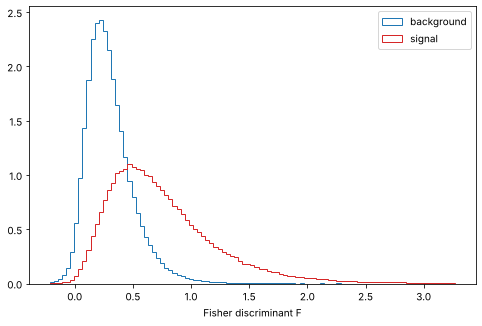

In [ ]:
def fisher_scores(names):
    m1, m2, SB, SW = fisher_matrices(names)
    w = np.linalg.solve(SW, m2 - m1)
    w = w / np.linalg.norm(w)
    fs = (df_sig[names].to_numpy() * w).sum(axis=1)
    fb = (df_bkg[names].to_numpy() * w).sum(axis=1)
    sgn = 1.0 if fs.mean() > fb.mean() else -1.0
    return w, sgn, sgn * fs, sgn * fb


w, sgn, Fs, Fb = fisher_scores(AllNames)
display(pd.DataFrame({"observable": AllNames, "w": w}).round(4))
print("F was multiplied by", int(sgn), "so that larger F means more signal-like (this does not change the ROC curve)")
plt.figure(figsize=(8, 5))
edges = np.linspace(np.percentile(np.concatenate([Fs, Fb]), 0.1), np.percentile(np.concatenate([Fs, Fb]), 99.9), 100)
plt.hist(Fb, bins=edges, density=True, histtype="step", color="tab:blue", label="background")
plt.hist(Fs, bins=edges, density=True, histtype="step", color="tab:red", label="signal")
plt.xlabel("Fisher discriminant F")
plt.legend()
plt.show()

**Answer (8.2):** The background distribution of F is narrow and peaks at low values. The signal distribution is broader, shifted to higher F, and has a long tail. They overlap mainly around the background peak, and above it the sample is mostly signal. (w is normalised to unit length; only its direction matters, so this does not change any efficiency or ROC curve.)

#### Exercise 8.3

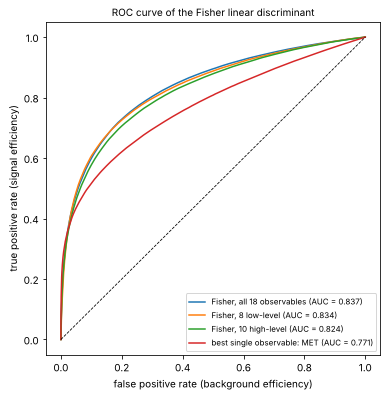

In [ ]:
curves = {"Fisher, all 18 observables": (Fs, Fb)}
for label, names in (("Fisher, 8 low-level", LowNames), ("Fisher, 10 high-level", HighNames)):
    _, _, fs_, fb_ = fisher_scores(names)
    curves[label] = (fs_, fb_)
curves[f"best single observable: {Top3[0]}"] = score_arrays(Top3[0])
aucs = roc_figure(curves, "ROC curve of the Fisher linear discriminant")

**Answer (8.3):** AUC: Fisher on all 18 observables 0.837, on the 8 low-level ones 0.834, on the 10 high-level ones 0.824; the best single observable (`MET`) is 0.771. A linear combination of the 8 raw measurements does as well as using everything and better than the 10 hand-made features. This matches the paper's point that the information is already in the low-level data. Note that w was computed and evaluated on the same 500k events; with only 18 coefficients, overfitting is negligible.

#### Exercise 8.4

In [ ]:
def max_significance(ss, sb, n=2000):
    ss, sb = np.sort(ss), np.sort(sb)
    thr = np.quantile(np.concatenate([ss, sb]), np.linspace(0.001, 0.999, n))
    es = 1 - np.searchsorted(ss, thr, side="right") / len(ss)
    eb = 1 - np.searchsorted(sb, thr, side="right") / len(sb)
    rows = []
    for sc, (ns, nb) in SCENARIOS.items():
        z = significance(es, eb, ns, nb)
        i = int(np.argmax(z))
        rows.append([sc, ns, nb, thr[i], es[i], eb[i], es[i] * ns, eb[i] * nb, z[i]])
    return rows


fisher_rows = max_significance(Fs, Fb)
show_table(fisher_rows, ["scenario", "N_S", "N_B", "cut on F", "ε_S", "ε_B", "N'_S", "N'_B", "σ_S'"])
show_table([[sc, max(Best[(v, sc)][3] for v in AllNames), cut_flow(sc, Chosen[sc])[-1][-1], fisher_rows[sc - 1][-1]]
            for sc in SCENARIOS],
           ["scenario", "best single observable", "cut flow (Exercise 6)", "Fisher discriminant"])

scenario,N_S,N_B,cut on F,ε_S,ε_B,N'_S,N'_B,σ_S'
1,10,100,0.6669,0.4918,0.05381,4.918,5.381,1.532
2,100,1000,0.6669,0.4918,0.05381,49.18,53.81,4.846
3,1000,10000,0.6669,0.4918,0.05381,491.8,538.1,15.32
4,10000,100000,0.6669,0.4918,0.05381,4918,5381,48.46


scenario,best single observable,cut flow (Exercise 6),Fisher discriminant
1,1.499,0.9761,1.532
2,4.74,3.087,4.846
3,14.99,9.761,15.32
4,47.4,30.87,48.46


**Answer (8.4):** The maximal significance with the Fisher discriminant is sigma = 1.53, 4.85, 15.32 and 48.46 for the four scenarios, at eps_S = 0.49 and eps_B = 0.054 (the same cut in all four, again because N_B/N_S = 10). This beats the best single cut (`MET`: 1.50, 4.74, 14.99, 47.4) and clearly beats the 4-cut flow from Exercise 6 (0.98, 3.09, 9.76, 30.87). The gain over `MET` is small for the significance even though the AUC rises from 0.771 to 0.837, because sigma depends only on the single best working point and not on the whole curve.